In [6]:
# Summary of receptor status among all 262 Griffin patients based on Primary/metastatic diagnosis and TFx counts
from pathlib import Path
import re
import pandas as pd


# ============================================================
# 1. Input files
# ============================================================

AURORA_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA"
)

FIRST_PRIMARY_METASHEET_PATH = (
    AURORA_DIR
    / "Clinical_data"
    / "Metasheet_Analysis.with_Histology_Receptor_status.First_Primary.xlsx"
)

EARLIEST_MET_METASHEET_PATH = (
    AURORA_DIR
    / "Clinical_data"
    / "Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx"
)

STATUS_ORDER = ["Positive", "Negative", "Unknown"]


# ============================================================
# 2. Helper functions
# ============================================================

def normalize_patient_id(value):
    """Normalize patient IDs read as strings or numbers."""
    if pd.isna(value):
        return ""
    return re.sub(r"\.0$", "", str(value).strip())


def normalize_sample(value):
    """Remove an optional AUP- prefix from sample IDs."""
    if pd.isna(value):
        return ""
    return re.sub(r"^AUP-", "", str(value).strip())


def nb_number(sample):
    """Extract the NB number for chronological first-draw selection."""
    match = re.search(r"-NB(\d+)$", str(sample))
    return int(match.group(1)) if match else 10**9


def normalize_status(value):
    """Normalize receptor status."""
    if pd.isna(value):
        return "Unknown"

    text = str(value).strip().lower()

    if text in {"positive", "pos", "+", "1", "yes", "true"}:
        return "Positive"

    if text in {"negative", "neg", "-", "0", "no", "false"}:
        return "Negative"

    return "Unknown"


def derive_molecular_subtype(er, pr, her2):
    """Derive HR/HER2 molecular subtype."""

    if her2 == "Unknown" or (er == "Unknown" and pr == "Unknown"):
        return "Unknown"

    hr_positive = er == "Positive" or pr == "Positive"
    hr_negative = er == "Negative" and pr == "Negative"

    if hr_positive and her2 == "Negative":
        return "HR+/HER2-"

    if hr_positive and her2 == "Positive":
        return "HR+/HER2+"

    if hr_negative and her2 == "Negative":
        return "HR-/HER2-"

    if hr_negative and her2 == "Positive":
        return "HR-/HER2+"

    return "Unknown"


def one_value_per_patient(group, column_name, patient_id):
    """
    Return one receptor value per patient.

    Stop if one patient has conflicting non-missing values.
    """
    values = []

    for value in group:
        if pd.isna(value):
            continue

        text = str(value).strip()

        if text.lower() not in {"", "none", "nan", "na", "n/a"}:
            values.append(text)

    unique_values = list(dict.fromkeys(values))

    if len(unique_values) > 1:
        raise ValueError(
            f"Patient {patient_id} has inconsistent {column_name} values: "
            f"{unique_values}"
        )

    return unique_values[0] if unique_values else pd.NA


def collapse_receptor_metasheet(metasheet, source_name):
    """Collapse repeated sample rows to one receptor row per patient."""

    required_columns = {
        "Patient_id",
        "ER_Status",
        "PR_Status",
        "HER2_Status",
    }

    missing = required_columns - set(metasheet.columns)

    if missing:
        raise ValueError(
            f"{source_name} metasheet is missing columns: {sorted(missing)}"
        )

    data = metasheet.copy()
    data["patient_id"] = data["Patient_id"].map(normalize_patient_id)

    patient_rows = []

    for patient_id, group in data.groupby("patient_id", sort=False):

        er = normalize_status(
            one_value_per_patient(
                group["ER_Status"],
                "ER_Status",
                patient_id,
            )
        )

        pr = normalize_status(
            one_value_per_patient(
                group["PR_Status"],
                "PR_Status",
                patient_id,
            )
        )

        her2 = normalize_status(
            one_value_per_patient(
                group["HER2_Status"],
                "HER2_Status",
                patient_id,
            )
        )

        patient_rows.append(
            {
                "patient_id": patient_id,
                f"{source_name}_ER": er,
                f"{source_name}_PR": pr,
                f"{source_name}_HER2": her2,
                f"{source_name}_subtype": derive_molecular_subtype(
                    er,
                    pr,
                    her2,
                ),
            }
        )

    return (
        pd.DataFrame(patient_rows)
        .sort_values("patient_id")
        .reset_index(drop=True)
    )


def print_status_summary(patient_table, source_label, source_prefix):
    """Print ER, PR, HER2, and molecular-subtype distributions."""

    print("\n" + "=" * 78)
    print(f"{source_label}: receptor status among all 262 Griffin patients")
    print("=" * 78)

    denominator = patient_table.shape[0]

    for marker in ["ER", "PR", "HER2"]:

        column = f"{source_prefix}_{marker}"

        table = (
            patient_table[column]
            .value_counts(dropna=False)
            .reindex(STATUS_ORDER, fill_value=0)
            .rename_axis("Status")
            .reset_index(name="N")
        )

        table["Percent"] = 100 * table["N"] / denominator

        print(f"\n{marker} status")
        print(
            table.to_string(
                index=False,
                formatters={"Percent": "{:.1f}".format},
            )
        )

    subtype_column = f"{source_prefix}_subtype"

    subtype_table = (
        patient_table[subtype_column]
        .value_counts(dropna=False)
        .rename_axis("Subtype")
        .reset_index(name="N")
    )

    subtype_table["Percent"] = 100 * subtype_table["N"] / denominator

    print("\nMolecular subtype")
    print(
        subtype_table.to_string(
            index=False,
            formatters={"Percent": "{:.1f}".format},
        )
    )


# ============================================================
# 3. Load receptor metasheets
# ============================================================

primary_meta = pd.read_excel(FIRST_PRIMARY_METASHEET_PATH)
metastatic_meta = pd.read_excel(EARLIEST_MET_METASHEET_PATH)

primary_receptors = collapse_receptor_metasheet(
    primary_meta,
    source_name="primary",
)

metastatic_receptors = collapse_receptor_metasheet(
    metastatic_meta,
    source_name="metastatic",
)


# Confirm that both metasheets contain the same patients
primary_ids = set(primary_receptors["patient_id"])
metastatic_ids = set(metastatic_receptors["patient_id"])

if primary_ids != metastatic_ids:
    raise ValueError(
        "Primary and metastatic metasheets do not contain the same patients."
    )


patient_receptors = primary_receptors.merge(
    metastatic_receptors,
    on="patient_id",
    how="inner",
    validate="one_to_one",
)

if patient_receptors.shape[0] != 262:
    raise ValueError(
        f"Expected 262 Griffin patients, found "
        f"{patient_receptors.shape[0]}."
    )


# ============================================================
# 4. Print primary and metastatic receptor distributions
# ============================================================

print_status_summary(
    patient_receptors,
    source_label="First primary diagnosis",
    source_prefix="primary",
)

print_status_summary(
    patient_receptors,
    source_label="Earliest metastatic diagnosis",
    source_prefix="metastatic",
)


# ============================================================
# 5. Primary versus metastatic ER concordance
# ============================================================

er_concordance = pd.crosstab(
    patient_receptors["primary_ER"],
    patient_receptors["metastatic_ER"],
    dropna=False,
).reindex(
    index=STATUS_ORDER,
    columns=STATUS_ORDER,
    fill_value=0,
)

print("\n" + "=" * 78)
print("Primary versus metastatic ER concordance")
print("=" * 78)
print(er_concordance.to_string())


known_both_er = patient_receptors[
    patient_receptors["primary_ER"].isin(["Positive", "Negative"])
    & patient_receptors["metastatic_ER"].isin(["Positive", "Negative"])
].copy()

known_both_er["ER_transition"] = (
    known_both_er["primary_ER"]
    + " -> "
    + known_both_er["metastatic_ER"]
)

transition_order = [
    "Positive -> Positive",
    "Negative -> Negative",
    "Positive -> Negative",
    "Negative -> Positive",
]

transition_counts = (
    known_both_er["ER_transition"]
    .value_counts()
    .reindex(transition_order, fill_value=0)
)

print("\nKnown primary and metastatic ER:", known_both_er.shape[0])
print(transition_counts.to_string())


# ============================================================
# 6. Longitudinal and first-draw tumor-fraction counts
# ============================================================

required_tfx_columns = {
    "Patient_id",
    "Collaborator_sample_id",
    "Tumor_Fraction",
}

missing_tfx_columns = required_tfx_columns - set(primary_meta.columns)

if missing_tfx_columns:
    raise ValueError(
        "Primary metasheet is missing TFx columns: "
        f"{sorted(missing_tfx_columns)}"
    )


# One TFx value per longitudinal plasma sample
sample_tfx = primary_meta.copy()

sample_tfx["patient_id"] = (
    sample_tfx["Patient_id"].map(normalize_patient_id)
)

sample_tfx["sample"] = (
    sample_tfx["Collaborator_sample_id"].map(normalize_sample)
)

sample_tfx["tumor_fraction"] = pd.to_numeric(
    sample_tfx["Tumor_Fraction"],
    errors="coerce",
)

sample_tfx = sample_tfx[
    ["patient_id", "sample", "tumor_fraction"]
].drop_duplicates()

all_sample_tfx = sample_tfx["tumor_fraction"]


# Select the earliest NB sample for each patient
first_draw = sample_tfx.copy()
first_draw["NB_number"] = first_draw["sample"].map(nb_number)

first_draw = (
    first_draw
    .sort_values(["patient_id", "NB_number", "sample"])
    .drop_duplicates("patient_id", keep="first")
)

if first_draw.shape[0] != 262:
    raise ValueError(
        f"Expected 262 first draws, found {first_draw.shape[0]}."
    )


print("\n" + "=" * 78)
print("Tumor-fraction counts: longitudinal samples versus first draws")
print("=" * 78)

print(
    "All longitudinal samples:",
    int(all_sample_tfx.notna().sum()),
)

print(
    "All longitudinal samples with TFx =0:",
    int((all_sample_tfx == 0).sum()),
)

print(
    "All longitudinal samples with TFx <3%:",
    int((all_sample_tfx < 0.03).sum()),
)

print(
    "All longitudinal samples with TFx <5%:",
    int((all_sample_tfx < 0.05).sum()),
)

print(
    "All longitudinal samples with 0<TFx<5%:",
    int(
        (
            (all_sample_tfx > 0)
            & (all_sample_tfx < 0.05)
        ).sum()
    ),
)

print("\nFirst draw per patient:")

print(
    "All 262 first draws with TFx =0:",
    int((first_draw["tumor_fraction"] == 0).sum()),
)

print(
    "All 262 first draws with TFx <3%:",
    int((first_draw["tumor_fraction"] < 0.03).sum()),
)

print(
    "All 262 first draws with TFx <5%:",
    int((first_draw["tumor_fraction"] < 0.05).sum()),
)


First primary diagnosis: receptor status among all 262 Griffin patients

ER status
  Status   N Percent
Positive 209    79.8
Negative  50    19.1
 Unknown   3     1.1

PR status
  Status   N Percent
Positive 182    69.5
Negative  75    28.6
 Unknown   5     1.9

HER2 status
  Status   N Percent
Positive  39    14.9
Negative 211    80.5
 Unknown  12     4.6

Molecular subtype
  Subtype   N Percent
HR+/HER2- 174    66.4
HR-/HER2-  37    14.1
HR+/HER2+  31    11.8
  Unknown  12     4.6
HR-/HER2+   8     3.1

Earliest metastatic diagnosis: receptor status among all 262 Griffin patients

ER status
  Status   N Percent
Positive 181    69.1
Negative  59    22.5
 Unknown  22     8.4

PR status
  Status   N Percent
Positive  99    37.8
Negative 138    52.7
 Unknown  25     9.5

HER2 status
  Status   N Percent
Positive  25     9.5
Negative 215    82.1
 Unknown  22     8.4

Molecular subtype
  Subtype   N Percent
HR+/HER2- 165    63.0
HR-/HER2-  50    19.1
  Unknown  22     8.4
HR+/HER2+  19   

Receptor source: First_Primary
Clinical file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx
Clinical sheet: AUP_ClinicalData_20260609.NO.DA
Griffin file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/Griffin_22TF_GC_corrected_summary_by_module.xlsx
Metasheet: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.First_Primary.xlsx
Metasheet sheet: Sheet1
Output: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_features_Primary_vs_Metastatic_ER/Griffin_BreastLineage_First_Primary_ER_Analysis.xlsx


/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/statsmodels/genmod/generalized_estimating_equations.py:1831: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_robust))
/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/statsmodels/genmod/generalized_estimating_equations.py:1831: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_robust))
/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/statsmodels/genmod/generalized_estimating_equations.py:1831: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_robust))
/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/statsmodels/genmod/generalized_estimating_equations.py:1831: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_robust))
/ihome/alee/rak373/.conda/envs/RegionalFragmentA

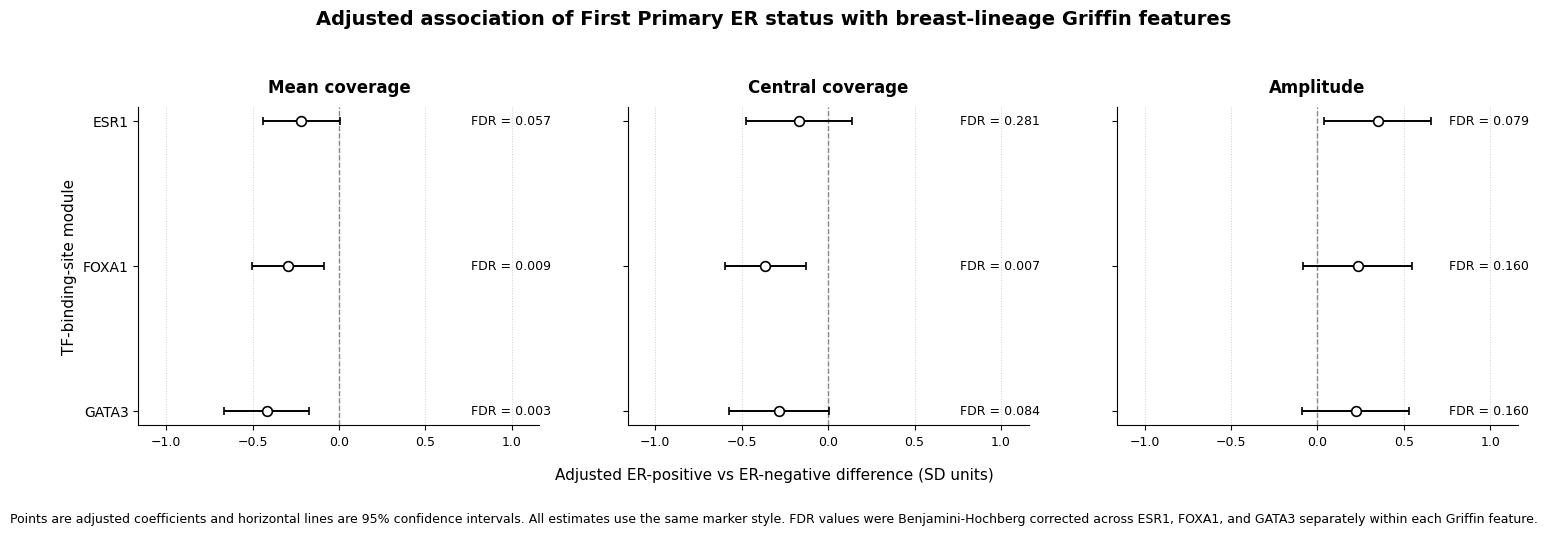


Selected-source ER counts:
  Positive: 209
  Negative: 50
  Unknown: 3

Primary complete-case model:
  Patients: 255
  ER-positive: 205
  ER-negative: 50

Primary module-level results:


,Feature,Average_ERpos_vs_ERneg_beta_SD,P_average,P_joint_ER_effect,FDR_joint_3features,P_interaction
0,Mean coverage,-0.308939,0.000617,0.002797,0.004214,0.231834
1,Central coverage,-0.271855,0.006807,0.002809,0.004214,0.233661
2,Amplitude,0.267565,0.004645,0.038777,0.038777,0.953007



Output created:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_features_Primary_vs_Metastatic_ER/Griffin_BreastLineage_First_Primary_ER_Analysis.xlsx


In [17]:
"""
AURORA Griffin breast-lineage analysis (ER+ vs ER-)
==============================================

Purpose
-------
Compare Griffin nucleosome features at ESR1, FOXA1, and GATA3 TF-binding
sites between ER-positive and ER-negative breast-cancer cases.

The analysis uses one first cfDNA blood draw per patient and supports two
receptor-status definitions through one switch:

    RECEPTOR_SOURCE = "First_Primary"
or
    RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"

Primary analysis
----------------
1. Select the lowest available NB blood draw for every patient (First draw).
2. Obtain ER, PR, HER2, and histology from the selected receptor source.
3. Compare ER-positive versus ER-negative cases.
4. Analyze mean coverage, central coverage, and amplitude separately.
5. Fit:
   - module-level Gaussian GEE across ESR1, FOXA1, and GATA3;
   - TF-specific HC3-robust linear regression.
6. Adjust for:
   - native tumor fraction per 1 percentage-point increase;
   - treatment context;
   - metastatic burden;
   - HER2 status;
   - histology;
   - years from metastatic diagnosis to the first draw.
7. Run sensitivity analyses:
   - clinical center plus corresponding CTCF feature;
   - HER2-negative-only cohort.
8. If the selected-source counts and complete-case model do not match, 
    - the difference is due to exclusion of patients with missing or unknown receptor status and/or missing at least one required covariate"
"""
# ============================================================
# 1. Imports
# ============================================================

import re
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter
from statsmodels.genmod.cov_struct import Independence
from statsmodels.genmod.families import Gaussian
from statsmodels.stats.multitest import multipletests

# ============================================================
# 2. USER SETTINGS
# ============================================================

# Receptor/subtype source switch.
#
# Use:
#     "First_Primary"
# for receptor status recorded for the original primary tumor.
#
# Use:
#     "Earliest_Met_Diagnosis"
# for receptor status recorded at the earliest metastatic-diagnosis row.
RECEPTOR_SOURCE = "First_Primary"

VALID_RECEPTOR_SOURCES = {
    "First_Primary",
    "Earliest_Met_Diagnosis",
}

if RECEPTOR_SOURCE not in VALID_RECEPTOR_SOURCES:
    raise ValueError(
        "Invalid RECEPTOR_SOURCE: {}. Allowed values: {}".format(
            RECEPTOR_SOURCE,
            sorted(VALID_RECEPTOR_SOURCES),
        )
    )


# Canonical project paths.
AURORA_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA"
)

PROJECT_DIR = (
    AURORA_DIR
    / "Griffin"
    / "griffin_nucleosome_profiling"
)

CLINICAL_PATH = (
    AURORA_DIR
    / "Clinical_data"
    / "AUP_ClinicalData_20260609.xlsx"
)

GRIFFIN_PATH = (
    PROJECT_DIR
    / "Griffin_22TF_GC_corrected_summary_by_module.xlsx"
)

# One canonical metasheet path only.
# Edit this one line if the metasheet is renamed or moved.
METASHEET_PATH = (
    AURORA_DIR
    / "Clinical_data"
    / "Metasheet_Analysis.with_Histology_Receptor_status.First_Primary.xlsx"
)

OUTPUT_DIR = (
    AURORA_DIR
    / "Griffin"
    / "Downstream"
    / "Griffin_features_Primary_vs_Metastatic_ER"
)

OUTPUT_PATH = (
    OUTPUT_DIR
    / (
        "Griffin_BreastLineage_"
        + RECEPTOR_SOURCE
        + "_ER_Analysis.xlsx"
    )
)

FOREST_PNG = (
    OUTPUT_DIR
    / (
        "Griffin_BreastLineage_"
        + RECEPTOR_SOURCE
        + "_ER_Adjusted_Forest.png"
    )
)

FOREST_PDF = (
    OUTPUT_DIR
    / (
        "Griffin_BreastLineage_"
        + RECEPTOR_SOURCE
        + "_ER_Adjusted_Forest.pdf"
    )
)


# Analysis settings.
TARGET_TFBS = ["ESR1", "FOXA1", "GATA3"]

FEATURES = {
    "mean_coverage": "Mean coverage",
    "central_coverage": "Central coverage",
    "amplitude": "Amplitude",
}

THERAPY_CATEGORIES = {
    "Met_Targeted_Therapy",
    "Met_Chemotherapy",
    "Met_Hormonal_Therapy",
}

# Keep known ambiguous treatment records visible and reproducible.
TREATMENT_CONTEXT_OVERRIDES = {
    "588-6": "Unknown",
    "995-4": "Unknown",
}

STATUS_ORDER = ["Negative", "Positive", "Unknown"]
HISTOLOGY_ORDER = ["Ductal", "Lobular", "Mixed", "Unknown"]
TREATMENT_ORDER = [
    "Pre-treatment",
    "On-treatment",
    "Post/Off-treatment",
    "Unknown",
]


# %%
# ============================================================
# 3. General utility functions
# ============================================================

def require_file(path: Path, label: str) -> None:
    """Stop immediately when a required input file is absent."""
    if not path.is_file():
        raise FileNotFoundError(
            "{} not found:\n{}".format(label, path)
        )


def find_sheet_with_columns(
    workbook_path: Path,
    required_columns: Iterable[str],
) -> str:
    """
    Return the first Excel sheet containing every required column.

    This avoids hard-coding an Excel sheet name while still requiring
    a precise table structure.
    """
    required = set(required_columns)
    workbook = pd.ExcelFile(workbook_path)

    for sheet_name in workbook.sheet_names:
        columns = set(
            pd.read_excel(
                workbook_path,
                sheet_name=sheet_name,
                nrows=0,
            ).columns
        )

        if required.issubset(columns):
            return sheet_name

    raise ValueError(
        "No sheet in {} contains all required columns: {}".format(
            workbook_path,
            sorted(required),
        )
    )


def normalize_patient_id(value: object) -> str:
    """Normalize patient identifiers read as either text or numeric."""
    if pd.isna(value):
        return ""

    text = str(value).strip()
    text = re.sub(r"\.0$", "", text)
    return text


def normalize_sample(value: object) -> str:
    """Convert AUP-XXX-NB1 to XXX-NB1 for cross-file matching."""
    if pd.isna(value):
        return ""

    sample = str(value).strip()
    sample = re.sub(r"^AUP-", "", sample)
    return sample


def nb_number(sample: object) -> int:
    """
    Extract the NB number from a sample ID.

    Examples
    --------
    123-4-NB1 -> 1
    123-4-NB3 -> 3

    Samples without an NB suffix are sorted last.
    """
    match = re.search(r"-NB(\d+)$", str(sample))

    if not match:
        return 10 ** 9

    return int(match.group(1))


def normalize_status(value: object) -> str:
    """Normalize ER/PR/HER2 values to Positive, Negative, or Unknown."""
    if pd.isna(value):
        return "Unknown"

    text = str(value).strip().lower()

    if text in {"positive", "pos", "+", "1", "yes"}:
        return "Positive"

    if text in {"negative", "neg", "-", "0", "no"}:
        return "Negative"

    return "Unknown"


def normalize_histology(value: object) -> str:
    """Collapse histology into Ductal, Lobular, Mixed, or Unknown."""
    if pd.isna(value):
        return "Unknown"

    text = str(value).strip().lower()

    if "mixed" in text:
        return "Mixed"

    if "lobular" in text:
        return "Lobular"

    if "ductal" in text:
        return "Ductal"

    return "Unknown"


def normalize_metastatic_site(value: object) -> Optional[str]:
    """
    Normalize metastatic-site labels for burden counting.

    Lung and pleura are combined. Soft tissue, skin, and chest wall are
    combined. Less common organs remain separate.
    """
    if pd.isna(value):
        return None

    site = re.sub(
        r"\s+",
        " ",
        str(value).strip().lower(),
    )

    if not site or site == "nan":
        return None

    if any(word in site for word in ["bone", "spine", "hip"]):
        return "Bone"

    if "liver" in site:
        return "Liver"

    if any(word in site for word in ["lung", "pleura", "pleural fluid"]):
        return "Lung/Pleura"

    if any(
        word in site
        for word in [
            "lymph node",
            "lymph nodes",
            "distant ln",
            "neck lymph",
            "prevascular node",
        ]
    ):
        return "Lymph node"

    if any(word in site for word in ["brain", "lepto", "spinal cord"]):
        return "CNS"

    if any(
        word in site
        for word in [
            "softtissue",
            "soft tissue",
            "skin",
            "chest wall",
            "brachial plexus",
            "supraclavicular mass",
            "breast",
        ]
    ):
        return "Soft tissue/Skin/Chest wall"

    if "adrenal" in site:
        return "Adrenal"

    if "ovary" in site:
        return "Ovary"

    if any(word in site for word in ["peritoneum", "ascites"]):
        return "Peritoneum/Ascites"

    if any(word in site for word in ["pericardial", "pericardium"]):
        return "Pericardium"

    if any(word in site for word in ["kidney", "ureter"]):
        return "Kidney/Ureter"

    if "spleen" in site:
        return "Spleen"

    if "thyroid" in site:
        return "Thyroid"

    if any(word in site for word in ["cervix", "endometrium"]):
        return "Gynecologic other"

    if "anorectal" in site:
        return "GI other"

    return site.title()


def bh_fdr(values: Iterable[float]) -> np.ndarray:
    """Benjamini-Hochberg FDR correction while preserving missing values."""
    values_array = np.asarray(list(values), dtype=float)
    corrected = np.full(values_array.shape, np.nan, dtype=float)
    valid = np.isfinite(values_array)

    if valid.any():
        corrected[valid] = multipletests(
            values_array[valid],
            method="fdr_bh",
        )[1]

    return corrected


def safe_quantile(
    series: pd.Series,
    probability: float,
) -> float:
    """Return a quantile, or NaN when a series has no numeric values."""
    values = pd.to_numeric(
        series,
        errors="coerce",
    ).dropna()

    if values.empty:
        return np.nan

    return float(values.quantile(probability))


def categorize_columns(data: pd.DataFrame) -> pd.DataFrame:
    """Set stable categorical reference levels for model reproducibility."""
    data = data.copy()

    data["ER"] = pd.Categorical(
        data["ER"],
        categories=["Negative", "Positive"],
    )

    data["HER2"] = pd.Categorical(
        data["HER2"],
        categories=STATUS_ORDER,
    )

    data["histology"] = pd.Categorical(
        data["histology"],
        categories=HISTOLOGY_ORDER,
    )

    data["treatment_context"] = pd.Categorical(
        data["treatment_context"],
        categories=TREATMENT_ORDER,
    )

    data["site_name"] = pd.Categorical(
        data["site_name"],
        categories=TARGET_TFBS,
        ordered=True,
    )

    return data


# %%
# ============================================================
# 4. Clinical-variable derivation
# ============================================================

def infer_treatment_context(
    patient_rows: pd.DataFrame,
    draw_day: float,
    patient_id: str,
) -> str:
    """
    Classify a blood draw as pre-treatment, on-treatment, or post/off.

    This uses structured metastatic-treatment start/end dates. When an
    end date is absent, the next treatment start or progression date is
    used as a conservative interval boundary.
    """
    if patient_id in TREATMENT_CONTEXT_OVERRIDES:
        return TREATMENT_CONTEXT_OVERRIDES[patient_id]

    therapy = patient_rows[
        patient_rows["Category"].isin(THERAPY_CATEGORIES)
    ].copy()

    metastatic_days = pd.to_numeric(
        patient_rows.loc[
            patient_rows["Category"].eq("Met_Diagnosis"),
            "Days_From_Primary_Diagnosis",
        ],
        errors="coerce",
    ).dropna()

    if therapy.empty:
        if (
            not metastatic_days.empty
            and draw_day >= metastatic_days.min()
        ):
            return "Unknown"

        return "Pre-treatment"

    therapy["start_day"] = pd.to_numeric(
        therapy["Days_From_Primary_Diagnosis"],
        errors="coerce",
    )

    therapy["end_day"] = pd.to_numeric(
        therapy["EndTrt_Days_From_Primary_Diagnosis"],
        errors="coerce",
    )

    therapy = (
        therapy
        .dropna(subset=["start_day"])
        .sort_values("start_day")
    )

    if therapy.empty:
        return "Unknown"

    start_days = sorted(
        therapy["start_day"].unique()
    )

    progression_days = pd.to_numeric(
        patient_rows.loc[
            patient_rows["Category"].eq("Progression_onTx"),
            "Days_From_Primary_Diagnosis",
        ],
        errors="coerce",
    ).dropna().sort_values()

    intervals = []

    for row in therapy.itertuples(index=False):
        start_day = float(row.start_day)
        end_day = row.end_day

        if pd.isna(end_day):
            possible_ends = [
                day
                for day in start_days
                if day > start_day
            ]

            possible_ends.extend(
                float(day)
                for day in progression_days
                if day >= start_day
            )

            if possible_ends:
                end_day = min(possible_ends) - 1e-6
            else:
                end_day = np.inf

        intervals.append(
            (start_day, float(end_day))
        )

    if any(
        start <= draw_day <= end
        for start, end in intervals
    ):
        return "On-treatment"

    if draw_day < min(
        start for start, _ in intervals
    ):
        return "Pre-treatment"

    return "Post/Off-treatment"


def select_receptor_rows(
    clinical: pd.DataFrame,
    receptor_source: str,
) -> pd.DataFrame:
    """
    Select one receptor-status row per patient.

    First_Primary
        Selects the earliest First_Primary row.

    Earliest_Met_Diagnosis
        Selects the earliest Met_Diagnosis row with an informative ER result.
        Blank or Unknown ER rows are skipped; if no informative ER is found,
        the patient is assigned Unknown after the later left join.
    """
    if receptor_source == "First_Primary":
        category = "First_Primary"
    elif receptor_source == "Earliest_Met_Diagnosis":
        category = "Met_Diagnosis"
    else:
        raise ValueError(
            "Unsupported receptor source: {}".format(
                receptor_source
            )
        )

    receptor_rows = clinical[
        clinical["Category"].eq(category)
    ].copy()

    if receptor_rows.empty:
        raise ValueError(
            "No clinical rows were found for Category='{}'.".format(
                category
            )
        )

    receptor_rows["source_day"] = pd.to_numeric(
        receptor_rows["Days_From_Primary_Diagnosis"],
        errors="coerce",
    )

    status_columns = [
        "ER_Status",
        "PR_Status",
        "HER2_Status",
    ]

    receptor_rows["status_completeness"] = (
        receptor_rows[status_columns]
        .notna()
        .sum(axis=1)
    )

    # For metastatic receptor status, skip Met_Diagnosis rows where ER is
    # blank or Unknown. The chronological sort below then selects the first
    # informative metastatic ER result. If no informative result exists,
    # the patient is absent here and becomes Unknown after the later left join.
    if receptor_source == "Earliest_Met_Diagnosis":
        receptor_rows["ER_normalized"] = receptor_rows[
            "ER_Status"
        ].map(normalize_status)

        receptor_rows = receptor_rows[
            receptor_rows["ER_normalized"].isin(
                ["Positive", "Negative"]
            )
        ].copy()

    receptor_rows = (
        receptor_rows
        .sort_values(
            [
                "patient_id",
                "source_day",
                "status_completeness",
            ],
            ascending=[True, True, False],
            na_position="last",
        )
        .drop_duplicates(
            subset=["patient_id"],
            keep="first",
        )
        [
            [
                "patient_id",
                "ER_Status",
                "PR_Status",
                "HER2_Status",
                "Histologic.type",
                "Site",
                "Tissue_Site",
                "source_day",
            ]
        ]
        .rename(
            columns={
                "ER_Status": "ER",
                "PR_Status": "PR",
                "HER2_Status": "HER2",
                "Histologic.type": "histology",
                "Site": "receptor_center",
                "Tissue_Site": "receptor_tissue_site",
                "source_day": "receptor_source_day",
            }
        )
    )

    receptor_rows["ER"] = receptor_rows[
        "ER"
    ].map(normalize_status)

    # Final agreed classification: keep patient 588-6 as metastatic ER-positive
    # (concordant with primary ER-positive).
    if receptor_source == "Earliest_Met_Diagnosis":
        receptor_rows.loc[
            receptor_rows["patient_id"].eq("588-6"),
            "ER",
        ] = "Positive"

    receptor_rows["PR"] = receptor_rows[
        "PR"
    ].map(normalize_status)

    receptor_rows["HER2"] = receptor_rows[
        "HER2"
    ].map(normalize_status)

    receptor_rows["histology"] = receptor_rows[
        "histology"
    ].map(normalize_histology)

    receptor_rows["receptor_source"] = receptor_source

    return receptor_rows


def build_first_draw_audit(
    clinical: pd.DataFrame,
    metasheet: pd.DataFrame,
    receptor_source: str,
) -> pd.DataFrame:
    """
    Build one analysis row per patient's first cfDNA draw.

    The audit table links:
    - first NB sample;
    - receptor status from the selected source;
    - tumor fraction;
    - treatment context;
    - metastatic burden;
    - time from metastatic diagnosis;
    - clinical center.
    """
    required_meta = {
        "Collaborator_sample_id",
        "Patient_id",
        "Patient_Identifier",
        "Tumor_Fraction",
    }

    missing_meta = required_meta - set(
        metasheet.columns
    )

    if missing_meta:
        raise ValueError(
            "Metasheet is missing columns: {}".format(
                sorted(missing_meta)
            )
        )

    metadata = metasheet.copy()

    metadata["sample"] = metadata[
        "Collaborator_sample_id"
    ].map(normalize_sample)

    metadata["patient_id"] = metadata[
        "Patient_id"
    ].map(normalize_patient_id)

    metadata["NB_number"] = metadata[
        "sample"
    ].map(nb_number)

    first_draw = (
        metadata
        .sort_values(
            [
                "patient_id",
                "NB_number",
                "sample",
            ]
        )
        .drop_duplicates(
            subset=["patient_id"],
            keep="first",
        )
        [
            [
                "patient_id",
                "Patient_Identifier",
                "sample",
                "Tumor_Fraction",
            ]
        ]
        .rename(
            columns={
                "Patient_Identifier": "patient_identifier",
                "Tumor_Fraction": "tumor_fraction",
            }
        )
    )

    clinical = clinical.copy()

    clinical["patient_id"] = clinical[
        "patient_id"
    ].map(normalize_patient_id)

    clinical["clinical_sample"] = clinical[
        "Barcode"
    ].map(normalize_sample)

    clinical["clinical_day"] = pd.to_numeric(
        clinical["Days_From_Primary_Diagnosis"],
        errors="coerce",
    )

    blood_draws = (
        clinical[
            clinical["Category"].eq("Blood_Draw")
        ]
        [
            [
                "patient_id",
                "clinical_sample",
                "clinical_day",
                "Site",
            ]
        ]
        .drop_duplicates(
            subset=[
                "patient_id",
                "clinical_sample",
            ],
            keep="first",
        )
        .rename(
            columns={
                "clinical_sample": "sample",
                "clinical_day": "draw_day",
                "Site": "clinical_center",
            }
        )
    )

    first_draw = first_draw.merge(
        blood_draws,
        on=["patient_id", "sample"],
        how="left",
        validate="one_to_one",
    )

    if first_draw["draw_day"].isna().any():
        missing_samples = first_draw.loc[
            first_draw["draw_day"].isna(),
            "sample",
        ].tolist()

        raise ValueError(
            "Could not match first draws to the clinical file: {}".format(
                ", ".join(missing_samples[:20])
            )
        )

    receptor_rows = select_receptor_rows(
        clinical=clinical,
        receptor_source=receptor_source,
    )

    audit = first_draw.merge(
        receptor_rows,
        on="patient_id",
        how="left",
        validate="one_to_one",
    )

    for column in ["ER", "PR", "HER2", "histology"]:
        audit[column] = audit[column].fillna("Unknown")

    audit["receptor_source"] = audit[
        "receptor_source"
    ].fillna(receptor_source)

    audit["clinical_center"] = (
        audit["clinical_center"]
        .fillna(audit["receptor_center"])
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

    clinical_by_patient = {
        patient_id: patient_rows.copy()
        for patient_id, patient_rows
        in clinical.groupby("patient_id")
    }

    metastatic_rows = (
        clinical[
            clinical["Category"].eq("Met_Diagnosis")
        ]
        [
            [
                "patient_id",
                "clinical_day",
                "Tissue_Site",
            ]
        ]
        .copy()
    )

    metastatic_rows["organ_category"] = metastatic_rows[
        "Tissue_Site"
    ].map(normalize_metastatic_site)

    metastatic_by_patient = {
        patient_id: patient_rows.copy()
        for patient_id, patient_rows
        in metastatic_rows.groupby("patient_id")
    }

    treatment_context = []
    metastatic_burden = []
    years_from_metastatic_diagnosis = []

    for row in audit.itertuples(index=False):
        patient_rows = clinical_by_patient.get(
            row.patient_id,
            pd.DataFrame(columns=clinical.columns),
        )

        context = infer_treatment_context(
            patient_rows=patient_rows,
            draw_day=float(row.draw_day),
            patient_id=row.patient_id,
        )

        treatment_context.append(context)

        patient_metastases = metastatic_by_patient.get(
            row.patient_id,
            pd.DataFrame(
                columns=metastatic_rows.columns
            ),
        )

        prior_metastases = patient_metastases[
            patient_metastases["clinical_day"]
            <= float(row.draw_day)
        ]

        burden = (
            prior_metastases["organ_category"]
            .dropna()
            .nunique()
        )

        metastatic_days = patient_metastases[
            "clinical_day"
        ].dropna()

        if metastatic_days.empty:
            years_value = np.nan
        else:
            years_value = (
                float(row.draw_day)
                - float(metastatic_days.min())
            ) / 365.25

        # Ambiguous treatment timing is excluded from adjusted models.
        if context == "Unknown":
            burden = np.nan

        metastatic_burden.append(burden)
        years_from_metastatic_diagnosis.append(
            years_value
        )

    audit["treatment_context"] = treatment_context
    audit["metastatic_burden"] = metastatic_burden
    audit["years_from_met_dx"] = (
        years_from_metastatic_diagnosis
    )

    audit = audit[
        [
            "patient_id",
            "patient_identifier",
            "sample",
            "receptor_source",
            "receptor_source_day",
            "receptor_tissue_site",
            "ER",
            "PR",
            "HER2",
            "histology",
            "clinical_center",
            "tumor_fraction",
            "treatment_context",
            "metastatic_burden",
            "years_from_met_dx",
        ]
    ].copy()

    return (
        audit
        .sort_values("patient_id")
        .reset_index(drop=True)
    )


# %%
# ============================================================
# 5. Prepare modeling datasets
# ============================================================

def prepare_analysis_data(
    griffin_long: pd.DataFrame,
    audit: pd.DataFrame,
    restrict_her2_negative: bool = False,
    include_ctcf: bool = False,
) -> pd.DataFrame:
    """
    Merge Griffin results with the first-draw audit and standardize each
    Griffin feature within TFBS.

    Standardized coefficients are expressed in TF-specific SD units.
    """
    required_griffin = {
        "sample",
        "site_name",
        "mean_coverage",
        "central_coverage",
        "amplitude",
    }

    missing = required_griffin - set(
        griffin_long.columns
    )

    if missing:
        raise ValueError(
            "All_TFBS_Long is missing columns: {}".format(
                sorted(missing)
            )
        )

    target = griffin_long[
        griffin_long["site_name"].isin(TARGET_TFBS)
    ].copy()

    analysis = target.merge(
        audit,
        on="sample",
        how="inner",
        validate="many_to_one",
    )

    analysis = analysis[
        analysis["ER"].isin(
            ["Positive", "Negative"]
        )
    ].copy()

    if restrict_her2_negative:
        analysis = analysis[
            analysis["HER2"].eq("Negative")
        ].copy()

    # Tumor fraction is stored as a proportion:
    # 0.01 = 1%, 0.05 = 5%, and 0.10 = 10%.
    #
    # Convert to percentage points so that one regression unit represents
    # a 1-percentage-point increase in tumor fraction.
    analysis["tumor_fraction"] = pd.to_numeric(
        analysis["tumor_fraction"],
        errors="coerce",
    )

    analysis["tumor_fraction_percent"] = (
        analysis["tumor_fraction"] * 100
    )

    analysis["tumor_fraction_per1pct"] = (
        analysis["tumor_fraction_percent"]
    )

    complete_columns = [
        "tumor_fraction_per1pct",
        "treatment_context",
        "metastatic_burden",
        "histology",
        "years_from_met_dx",
    ]

    if not restrict_her2_negative:
        complete_columns.append("HER2")

    if include_ctcf:
        complete_columns.append("clinical_center")

        ctcf = griffin_long[
            griffin_long["site_name"].eq("CTCF")
        ][
            [
                "sample",
                "mean_coverage",
                "central_coverage",
                "amplitude",
            ]
        ].rename(
            columns={
                feature: "CTCF_{}".format(feature)
                for feature in FEATURES
            }
        )

        analysis = analysis.merge(
            ctcf,
            on="sample",
            how="left",
            validate="many_to_one",
        )

        complete_columns.extend(
            [
                "CTCF_{}".format(feature)
                for feature in FEATURES
            ]
        )

    analysis = analysis.dropna(
        subset=complete_columns
    ).copy()

    # Standardize outcomes after complete-case selection.
    for feature in FEATURES:
        analysis["{}_z".format(feature)] = (
            analysis
            .groupby("site_name")[feature]
            .transform(
                lambda values: (
                    values - values.mean()
                ) / values.std(ddof=0)
            )
        )

    if include_ctcf:
        unique_ctcf = analysis[
            [
                "sample",
                "CTCF_mean_coverage",
                "CTCF_central_coverage",
                "CTCF_amplitude",
            ]
        ].drop_duplicates("sample")

        for feature in FEATURES:
            column = "CTCF_{}".format(feature)

            mean_value = unique_ctcf[column].mean()
            sd_value = unique_ctcf[column].std(ddof=0)

            analysis["{}_z".format(column)] = (
                analysis[column] - mean_value
            ) / sd_value

    return categorize_columns(analysis)


def model_covariate_terms(
    restrict_her2_negative: bool,
    include_ctcf: bool,
    feature: Optional[str] = None,
) -> List[str]:
    """Return the covariate terms used by all models."""
    terms = [
        "tumor_fraction_per1pct",
        "C(treatment_context)",
        "metastatic_burden",
        "C(histology)",
        "years_from_met_dx",
    ]

    if not restrict_her2_negative:
        terms.append("C(HER2)")

    if include_ctcf:
        terms.append("C(clinical_center)")

        if feature is None:
            raise ValueError(
                "feature is required when include_ctcf=True"
            )

        terms.append(
            "CTCF_{}_z".format(feature)
        )

    return terms


# %%
# ============================================================
# 6. Statistical models
# ============================================================

def wald_for_terms(
    fit,
    selected_names: List[str],
) -> Tuple[float, int, float]:
    """Perform a joint Wald test for selected fitted coefficients."""
    parameter_names = list(fit.params.index)

    matrix = np.zeros(
        (
            len(selected_names),
            len(parameter_names),
        )
    )

    for row_index, name in enumerate(selected_names):
        matrix[
            row_index,
            parameter_names.index(name),
        ] = 1.0

    test = fit.wald_test(matrix)

    statistic = float(
        np.asarray(test.statistic).squeeze()
    )

    p_value = float(
        np.asarray(test.pvalue).squeeze()
    )

    return statistic, len(selected_names), p_value


def fit_module_models(
    analysis: pd.DataFrame,
    model_name: str,
    restrict_her2_negative: bool = False,
    include_ctcf: bool = False,
) -> pd.DataFrame:
    """
    Fit one GEE per Griffin feature across all three TFBSs.

    Sum coding for TFBS makes the ER main coefficient represent the
    average ER-positive versus ER-negative difference across ESR1,
    FOXA1, and GATA3.
    """
    records = []

    for feature, feature_label in FEATURES.items():
        terms = model_covariate_terms(
            restrict_her2_negative=restrict_her2_negative,
            include_ctcf=include_ctcf,
            feature=feature,
        )

        formula = (
            "{}_z ~ "
            "C(ER, Treatment(reference='Negative')) "
            "* C(site_name, Sum)"
        ).format(feature)

        if terms:
            formula += " + " + " + ".join(terms)

        fit = smf.gee(
            formula=formula,
            groups="patient_id",
            data=analysis,
            family=Gaussian(),
            cov_struct=Independence(),
        ).fit()

        parameter_names = list(fit.params.index)

        er_main_names = [
            name
            for name in parameter_names
            if name.startswith(
                "C(ER, Treatment(reference='Negative'))"
            )
            and ":" not in name
        ]

        interaction_names = [
            name
            for name in parameter_names
            if (
                "C(ER, Treatment(reference='Negative'))"
                in name
                and ":" in name
            )
        ]

        if len(er_main_names) != 1:
            raise RuntimeError(
                "Could not identify module-level ER coefficient."
            )

        er_name = er_main_names[0]

        interaction_chi2, interaction_df, interaction_p = (
            wald_for_terms(
                fit,
                interaction_names,
            )
        )

        joint_names = (
            er_main_names + interaction_names
        )

        joint_chi2, joint_df, joint_p = (
            wald_for_terms(
                fit,
                joint_names,
            )
        )

        records.append(
            {
                "Model": model_name,
                "Receptor_source": RECEPTOR_SOURCE,
                "Feature": feature_label,
                "N_patients": int(
                    analysis["patient_id"].nunique()
                ),
                "N_rows": int(len(analysis)),
                "Average_ERpos_vs_ERneg_beta_SD": float(
                    fit.params[er_name]
                ),
                "SE": float(fit.bse[er_name]),
                "P_average": float(
                    fit.pvalues[er_name]
                ),
                "Interaction_chi2": interaction_chi2,
                "Interaction_df": interaction_df,
                "P_interaction": interaction_p,
                "Joint_ER_chi2": joint_chi2,
                "Joint_ER_df": joint_df,
                "P_joint_ER_effect": joint_p,
                "Formula": formula,
            }
        )

    results = pd.DataFrame(records)

    results["FDR_joint_3features"] = bh_fdr(
        results["P_joint_ER_effect"]
    )

    results["FDR_average_3features"] = bh_fdr(
        results["P_average"]
    )

    results["FDR_interaction_3features"] = bh_fdr(
        results["P_interaction"]
    )

    return results


def fit_tf_specific_models(
    analysis: pd.DataFrame,
    model_name: str,
    restrict_her2_negative: bool = False,
    include_ctcf: bool = False,
) -> pd.DataFrame:
    """
    Fit separate HC3-robust linear models for ESR1, FOXA1, and GATA3.

    Because only one first blood draw is included, each TF-specific
    dataset contains one observation per patient.
    """
    records = []

    for feature, feature_label in FEATURES.items():
        terms = model_covariate_terms(
            restrict_her2_negative=restrict_her2_negative,
            include_ctcf=include_ctcf,
            feature=feature,
        )

        for tfbs in TARGET_TFBS:
            tf_data = analysis[
                analysis["site_name"]
                .astype(str)
                .eq(tfbs)
            ].copy()

            formula = (
                "{}_z ~ "
                "C(ER, Treatment(reference='Negative'))"
            ).format(feature)

            if terms:
                formula += " + " + " + ".join(terms)

            fit = smf.ols(
                formula=formula,
                data=tf_data,
            ).fit(
                cov_type="HC3"
            )

            er_names = [
                name
                for name in fit.params.index
                if name.startswith(
                    "C(ER, Treatment(reference='Negative'))"
                )
            ]

            if len(er_names) != 1:
                raise RuntimeError(
                    "Could not identify ER coefficient for {}.".format(
                        tfbs
                    )
                )

            er_name = er_names[0]
            beta = float(fit.params[er_name])
            standard_error = float(fit.bse[er_name])

            records.append(
                {
                    "Model": model_name,
                    "Receptor_source": RECEPTOR_SOURCE,
                    "Feature": feature_label,
                    "TFBS": tfbs,
                    "N": int(len(tf_data)),
                    "ERpos_vs_ERneg_beta_SD": beta,
                    "SE": standard_error,
                    "CI95_low": beta - 1.96 * standard_error,
                    "CI95_high": beta + 1.96 * standard_error,
                    "P_value": float(
                        fit.pvalues[er_name]
                    ),
                    "Formula": formula,
                }
            )

    results = pd.DataFrame(records)

    results["FDR_9tests"] = bh_fdr(
        results["P_value"]
    )

    results["FDR_within_feature"] = (
        results
        .groupby("Feature")["P_value"]
        .transform(
            lambda values: bh_fdr(values)
        )
    )

    return results


# %%
# ============================================================
# 7. Descriptive and methods tables
# ============================================================

def build_raw_descriptives(
    griffin_long: pd.DataFrame,
    audit: pd.DataFrame,
) -> pd.DataFrame:
    """Summarize raw Griffin values before standardization."""
    data = (
        griffin_long[
            griffin_long["site_name"].isin(TARGET_TFBS)
        ]
        .merge(
            audit,
            on="sample",
            how="inner",
        )
    )

    data = data[
        data["ER"].isin(
            ["Positive", "Negative"]
        )
    ].copy()

    records = []

    for (
        er_status,
        tfbs,
    ), group in data.groupby(
        ["ER", "site_name"],
        observed=True,
    ):
        for feature, feature_label in FEATURES.items():
            values = pd.to_numeric(
                group[feature],
                errors="coerce",
            ).dropna()

            records.append(
                {
                    "Receptor_source": RECEPTOR_SOURCE,
                    "ER_group": (
                        "ER-positive"
                        if er_status == "Positive"
                        else "ER-negative"
                    ),
                    "TFBS": tfbs,
                    "Feature": feature_label,
                    "N": int(len(values)),
                    "Mean": float(values.mean()),
                    "SD": float(values.std(ddof=1)),
                    "Median": float(values.median()),
                    "Q1": safe_quantile(values, 0.25),
                    "Q3": safe_quantile(values, 0.75),
                }
            )

    return pd.DataFrame(records)


def build_cohort_summary(
    audit: pd.DataFrame,
) -> pd.DataFrame:
    """Summarize the first-draw cohort by selected-source ER status."""
    data = audit[
        audit["ER"].isin(
            ["Positive", "Negative"]
        )
    ].copy()

    records = []

    for er_status, group in data.groupby(
        "ER",
        observed=True,
    ):
        tumor_fraction = pd.to_numeric(
            group["tumor_fraction"],
            errors="coerce",
        )

        records.append(
            {
                "Receptor_source": RECEPTOR_SOURCE,
                "ER_group": (
                    "ER-positive"
                    if er_status == "Positive"
                    else "ER-negative"
                ),
                "N_patients": int(
                    group["patient_id"].nunique()
                ),
                "Tumor_fraction_median": float(
                    tumor_fraction.median()
                ),
                "Tumor_fraction_Q1": safe_quantile(
                    tumor_fraction,
                    0.25,
                ),
                "Tumor_fraction_Q3": safe_quantile(
                    tumor_fraction,
                    0.75,
                ),
                "Met_burden_median": float(
                    pd.to_numeric(
                        group["metastatic_burden"],
                        errors="coerce",
                    ).median()
                ),
                "Time_since_met_dx_years_median": float(
                    pd.to_numeric(
                        group["years_from_met_dx"],
                        errors="coerce",
                    ).median()
                ),
                "PR_positive_n": int(
                    group["PR"].eq("Positive").sum()
                ),
                "PR_negative_n": int(
                    group["PR"].eq("Negative").sum()
                ),
                "HER2_positive_n": int(
                    group["HER2"].eq("Positive").sum()
                ),
                "HER2_negative_n": int(
                    group["HER2"].eq("Negative").sum()
                ),
                "Ductal_n": int(
                    group["histology"].eq("Ductal").sum()
                ),
                "Lobular_n": int(
                    group["histology"].eq("Lobular").sum()
                ),
                "Mixed_n": int(
                    group["histology"].eq("Mixed").sum()
                ),
                "Pre_treatment_n": int(
                    group["treatment_context"]
                    .eq("Pre-treatment")
                    .sum()
                ),
                "On_treatment_n": int(
                    group["treatment_context"]
                    .eq("On-treatment")
                    .sum()
                ),
                "Post_off_n": int(
                    group["treatment_context"]
                    .eq("Post/Off-treatment")
                    .sum()
                ),
            }
        )

    return pd.DataFrame(records)


def build_methods_table() -> pd.DataFrame:
    """Create a detailed, reproducible data dictionary for the analysis."""
    source_description = (
        "First_Primary clinical record"
        if RECEPTOR_SOURCE == "First_Primary"
        else "earliest Met_Diagnosis clinical record"
    )

    records = [
        {
            "Method item": "Receptor definition",
            "Description": (
                "ER, PR, HER2, and histology were taken from the "
                + source_description
                + "."
            ),
        },
        {
            "Method item": "Draw selection",
            "Description": (
                "The first available cfDNA blood draw was selected for each "
                "patient using the lowest NB number. The analysis is therefore "
                "not longitudinal; each patient contributes one blood draw."
            ),
        },
        {
            "Method item": "Unknown ER status",
            "Description": (
                "Patients with unknown ER status under the selected receptor "
                "source were excluded from ER-positive versus ER-negative models."
            ),
        },
        {
            "Method item": "Primary_Module",
            "Description": (
                "Primary module-level Gaussian GEE analysis. For each Griffin "
                "feature, ESR1, FOXA1, and GATA3 are treated as three correlated "
                "rows from the same first-draw sample and clustered by patient_id. "
                "This is repeated-TFBS, not repeated-time-point, modeling."
            ),
        },
        {
            "Method item": "Primary_TF_Posthoc",
            "Description": (
                "Primary TF-specific post hoc analysis. Separate HC3-robust linear "
                "regressions are fitted for ESR1, FOXA1, and GATA3 using one first "
                "draw per patient and the same adjustment covariates as the module model."
            ),
        },
        {
            "Method item": "Module model formula",
            "Description": (
                "Standardized Griffin feature ~ ER status × TFBS + native tumor "
                "fraction per 1 percentage points + treatment context + metastatic "
                "burden + HER2 + histology + years from metastatic diagnosis. "
                "TFBS is sum-coded so the ER main coefficient represents the average "
                "ER-positive versus ER-negative difference across ESR1, FOXA1, and GATA3."
            ),
        },
        {
            "Method item": "tumor_fraction_per1pct",
            "Description": (
                "Tumor fraction is stored as a proportion and converted to percentage "
                "points by multiplying by 100. One model unit therefore represents a "
                "1-percentage-point increase in tumor fraction; for example, 0.01 "
                "becomes 1, 0.05 becomes 5, and 0.10 becomes 10."
            ),
        },
        {
            "Method item": "Standardization",
            "Description": (
                "Each Griffin outcome was standardized within TFBS after complete-case "
                "selection. Effect estimates are expressed in TF-specific standard-"
                "deviation units."
            ),
        },
        {
            "Method item": "P_average",
            "Description": (
                "Module-level GEE P value for the average ER-positive versus ER-negative "
                "difference across ESR1, FOXA1, and GATA3. It tests the ER main effect "
                "under sum coding of TFBS."
            ),
        },
        {
            "Method item": "P_interaction",
            "Description": (
                "Module-level joint Wald-test P value for the ER × TFBS interaction "
                "terms. It tests whether the ER association differs among ESR1, FOXA1, "
                "and GATA3."
            ),
        },
        {
            "Method item": "P_joint_ER_effect",
            "Description": (
                "Module-level joint Wald-test P value for the ER main effect plus all "
                "ER × TFBS interaction terms. It tests whether ER status has any average "
                "or TFBS-specific association with the Griffin feature."
            ),
        },
        {
            "Method item": "FDR_average_3features",
            "Description": (
                "Benjamini-Hochberg correction of P_average across the three module "
                "outcomes: mean coverage, central coverage, and amplitude."
            ),
        },
        {
            "Method item": "FDR_interaction_3features",
            "Description": (
                "Benjamini-Hochberg correction of P_interaction across mean coverage, "
                "central coverage, and amplitude."
            ),
        },
        {
            "Method item": "FDR_joint_3features",
            "Description": (
                "Benjamini-Hochberg correction of P_joint_ER_effect across mean coverage, "
                "central coverage, and amplitude."
            ),
        },
        {
            "Method item": "FDR_9tests",
            "Description": (
                "Benjamini-Hochberg correction across all nine TF-specific comparisons: "
                "three TFBSs multiplied by three Griffin features. This is retained in "
                "the result sheets as the global TF-specific multiplicity correction."
            ),
        },
        {
            "Method item": "FDR_within_feature",
            "Description": (
                "Benjamini-Hochberg correction across ESR1, FOXA1, and GATA3 separately "
                "within each Griffin feature. These are the FDR values printed for all "
                "nine estimates in the main forest plot."
            ),
        },
        {
            "Method item": "CTCF_Module_Sensitivity",
            "Description": (
                "Module-level GEE sensitivity analysis that additionally adjusts for "
                "clinical center and the corresponding standardized CTCF Griffin feature. "
                "It assesses whether module-level ER associations persist after accounting "
                "for center effects and broader nucleosome-pattern variation."
            ),
        },
        {
            "Method item": "CTCF_TF_Sensitivity",
            "Description": (
                "TF-specific HC3 sensitivity analysis that additionally adjusts for "
                "clinical center and the corresponding standardized CTCF Griffin feature."
            ),
        },
        {
            "Method item": "HER2neg_Module",
            "Description": (
                "Module-level GEE sensitivity analysis restricted to patients whose "
                "selected-source HER2 status is negative. HER2 is not included as a "
                "covariate because the restricted cohort has one HER2 category."
            ),
        },
        {
            "Method item": "HER2neg_TF",
            "Description": (
                "TF-specific HC3 sensitivity analysis restricted to selected-source "
                "HER2-negative patients."
            ),
        },
        {
            "Method item": "Forest plot",
            "Description": (
                "The forest plot uses Primary_TF_Posthoc estimates. Every point is shown "
                "with the same open-circle marker, horizontal lines are 95% confidence "
                "intervals, and every estimate is labeled with FDR_within_feature. No "
                "significance-dependent marker highlighting is used."
            ),
        },
        {
            "Method item": "Interpretation guardrail",
            "Description": (
                "Central coverage and amplitude are inferred cfDNA nucleosome features; "
                "they do not directly measure transcription, TF occupancy, or chromatin "
                "accessibility."
            ),
        },
    ]

    return pd.DataFrame(records)


# %%
# ============================================================
# 8. Publication forest plot
# ============================================================

def plot_adjusted_tf_forest(
    results: pd.DataFrame,
    title: str,
    png_path: Path,
    pdf_path: Path,
) -> None:
    """
    Plot all TF-specific adjusted coefficients with 95% confidence intervals.

    Every estimate uses the same open-circle marker and is annotated with
    FDR_within_feature. No significance-dependent highlighting is applied.
    """
    required_columns = {
        "Feature",
        "TFBS",
        "ERpos_vs_ERneg_beta_SD",
        "CI95_low",
        "CI95_high",
        "FDR_within_feature",
    }

    missing_columns = required_columns - set(results.columns)
    if missing_columns:
        raise ValueError(
            "Forest-plot input is missing columns: {}".format(
                sorted(missing_columns)
            )
        )

    feature_order = [
        "Mean coverage",
        "Central coverage",
        "Amplitude",
    ]
    tfbs_order = ["ESR1", "FOXA1", "GATA3"]

    plot_data = results.copy()
    plot_data["Feature"] = pd.Categorical(
        plot_data["Feature"],
        categories=feature_order,
        ordered=True,
    )
    plot_data["TFBS"] = pd.Categorical(
        plot_data["TFBS"],
        categories=tfbs_order,
        ordered=True,
    )
    plot_data = plot_data.sort_values(["Feature", "TFBS"])

    numeric_limits = pd.concat(
        [
            pd.to_numeric(plot_data["CI95_low"], errors="coerce"),
            pd.to_numeric(plot_data["CI95_high"], errors="coerce"),
        ],
        ignore_index=True,
    ).dropna()

    if numeric_limits.empty:
        raise ValueError("No finite confidence intervals are available for plotting.")

    max_abs_ci = max(0.25, float(np.abs(numeric_limits).max()))
    coefficient_limit = max_abs_ci * 1.15
    total_limit = max_abs_ci * 1.75

    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(15.5, 5.4),
        sharex=True,
        sharey=True,
    )

    for axis, feature in zip(axes, feature_order):
        subset = (
            plot_data[plot_data["Feature"].eq(feature)]
            .set_index("TFBS")
            .reindex(tfbs_order)
            .reset_index()
        )

        y_positions = np.arange(len(tfbs_order))
        beta = pd.to_numeric(
            subset["ERpos_vs_ERneg_beta_SD"], errors="coerce"
        ).to_numpy(dtype=float)
        ci_low = pd.to_numeric(
            subset["CI95_low"], errors="coerce"
        ).to_numpy(dtype=float)
        ci_high = pd.to_numeric(
            subset["CI95_high"], errors="coerce"
        ).to_numpy(dtype=float)

        lower_error = beta - ci_low
        upper_error = ci_high - beta

        # Identical marker style for every estimate.
        axis.errorbar(
            beta,
            y_positions,
            xerr=[lower_error, upper_error],
            fmt="o",
            markersize=7,
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            ecolor="black",
            elinewidth=1.4,
            capsize=3,
            capthick=1.2,
            linestyle="none",
            zorder=3,
        )

        axis.axvline(
            0,
            linestyle="--",
            linewidth=1,
            color="gray",
            zorder=1,
        )

        # Label every estimate with FDR corrected across the three TFBSs
        # within the current Griffin feature.
        for row_index, row in subset.iterrows():
            fdr_value = pd.to_numeric(
                pd.Series([row["FDR_within_feature"]]),
                errors="coerce",
            ).iloc[0]

            if pd.isna(fdr_value):
                fdr_label = "FDR = NA"
            elif float(fdr_value) < 0.001:
                fdr_label = "FDR < 0.001"
            else:
                fdr_label = "FDR = {:.3f}".format(float(fdr_value))

            axis.text(
                coefficient_limit,
                row_index,
                fdr_label,
                ha="left",
                va="center",
                fontsize=9,
            )

        axis.set_title(feature, fontsize=12, fontweight="bold", pad=10)
        axis.set_yticks(y_positions)
        axis.set_yticklabels(tfbs_order, fontsize=10)
        axis.invert_yaxis()
        axis.set_xlim(-total_limit, total_limit)
        axis.grid(axis="x", linestyle=":", linewidth=0.7, alpha=0.6)
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)
        axis.tick_params(axis="x", labelsize=9)

    axes[0].set_ylabel("TF-binding-site module", fontsize=11)

    fig.supxlabel(
        "Adjusted ER-positive vs ER-negative difference (SD units)",
        fontsize=11,
        y=0.105,
    )
    fig.suptitle(title, fontsize=14, fontweight="bold", y=0.98)
    fig.text(
        0.5,
        0.025,
        (
            "Points are adjusted coefficients and horizontal lines are 95% confidence "
            "intervals. All estimates use the same marker style. FDR values were "
            "Benjamini-Hochberg corrected across ESR1, FOXA1, and GATA3 separately "
            "within each Griffin feature."
        ),
        ha="center",
        va="bottom",
        fontsize=9,
    )

    fig.subplots_adjust(
        left=0.09,
        right=0.98,
        top=0.80,
        bottom=0.21,
        wspace=0.22,
    )

    png_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# %%
# ============================================================
# 9. Excel formatting
# ============================================================

def format_workbook(output_path: Path) -> None:
    """Apply consistent filters, frozen headers, and readable widths."""
    from openpyxl import load_workbook

    workbook = load_workbook(output_path)

    header_fill = PatternFill(
        "solid",
        fgColor="1F4E78",
    )

    header_font = Font(
        bold=True,
        color="FFFFFF",
    )

    for worksheet in workbook.worksheets:
        worksheet.freeze_panes = "A2"

        for cell in worksheet[1]:
            cell.fill = header_fill
            cell.font = header_font
            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True,
            )

        worksheet.auto_filter.ref = (
            worksheet.dimensions
        )

        for column_cells in worksheet.columns:
            max_length = 0

            for cell in column_cells:
                if cell.value is not None:
                    max_length = max(
                        max_length,
                        len(str(cell.value)),
                    )

            width = min(
                max(max_length + 2, 12),
                45,
            )

            worksheet.column_dimensions[
                get_column_letter(
                    column_cells[0].column
                )
            ].width = width

    workbook.save(output_path)


# %%
# ============================================================
# 10. Load inputs
# ============================================================

require_file(
    CLINICAL_PATH,
    "Clinical workbook",
)

require_file(
    GRIFFIN_PATH,
    "Griffin summary workbook",
)

require_file(
    METASHEET_PATH,
    "Genomic metasheet",
)

clinical_sheet = find_sheet_with_columns(
    CLINICAL_PATH,
    [
        "patient_id",
        "Category",
        "Days_From_Primary_Diagnosis",
        "ER_Status",
        "PR_Status",
        "HER2_Status",
    ],
)

metasheet_sheet = find_sheet_with_columns(
    METASHEET_PATH,
    [
        "Collaborator_sample_id",
        "Patient_id",
        "Patient_Identifier",
        "Tumor_Fraction",
    ],
)

print("Receptor source:", RECEPTOR_SOURCE)
print("Clinical file:", CLINICAL_PATH)
print("Clinical sheet:", clinical_sheet)
print("Griffin file:", GRIFFIN_PATH)
print("Metasheet:", METASHEET_PATH)
print("Metasheet sheet:", metasheet_sheet)
print("Output:", OUTPUT_PATH)

clinical = pd.read_excel(
    CLINICAL_PATH,
    sheet_name=clinical_sheet,
)

metasheet = pd.read_excel(
    METASHEET_PATH,
    sheet_name=metasheet_sheet,
)

griffin_long = pd.read_excel(
    GRIFFIN_PATH,
    sheet_name="All_TFBS_Long",
)


# %%
# ============================================================
# 11. Build first-draw audit and modeling datasets
# ============================================================

audit = build_first_draw_audit(
    clinical=clinical,
    metasheet=metasheet,
    receptor_source=RECEPTOR_SOURCE,
)

primary_data = prepare_analysis_data(
    griffin_long=griffin_long,
    audit=audit,
    restrict_her2_negative=False,
    include_ctcf=False,
)

ctcf_data = prepare_analysis_data(
    griffin_long=griffin_long,
    audit=audit,
    restrict_her2_negative=False,
    include_ctcf=True,
)

her2_negative_data = prepare_analysis_data(
    griffin_long=griffin_long,
    audit=audit,
    restrict_her2_negative=True,
    include_ctcf=False,
)


# %%
# ============================================================
# 12. Fit models
# ============================================================

primary_module = fit_module_models(
    analysis=primary_data,
    model_name="Primary",
)

primary_tf = fit_tf_specific_models(
    analysis=primary_data,
    model_name="Primary",
)

ctcf_module = fit_module_models(
    analysis=ctcf_data,
    model_name="CTCF_center_sensitivity",
    include_ctcf=True,
)

ctcf_tf = fit_tf_specific_models(
    analysis=ctcf_data,
    model_name="CTCF_center_sensitivity",
    include_ctcf=True,
)

her2_negative_module = fit_module_models(
    analysis=her2_negative_data,
    model_name="HER2_negative_restricted",
    restrict_her2_negative=True,
)

her2_negative_tf = fit_tf_specific_models(
    analysis=her2_negative_data,
    model_name="HER2_negative_restricted",
    restrict_her2_negative=True,
)

cohort_summary = build_cohort_summary(
    audit
)

raw_descriptives = build_raw_descriptives(
    griffin_long=griffin_long,
    audit=audit,
)

methods = build_methods_table()

plot_adjusted_tf_forest(
    results=primary_tf,
    title=(
        "Adjusted association of "
        + RECEPTOR_SOURCE.replace("_", " ")
        + " ER status with breast-lineage Griffin features"
    ),
    png_path=FOREST_PNG,
    pdf_path=FOREST_PDF,
)


# %%
# ============================================================
# 13. Save one canonical Excel result workbook
# ============================================================

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

with pd.ExcelWriter(
    OUTPUT_PATH,
    engine="openpyxl",
) as writer:
    cohort_summary.to_excel(
        writer,
        sheet_name="Cohort_Summary",
        index=False,
    )

    primary_module.to_excel(
        writer,
        sheet_name="Primary_Module",
        index=False,
    )

    primary_tf.to_excel(
        writer,
        sheet_name="Primary_TF_Posthoc",
        index=False,
    )

    raw_descriptives.to_excel(
        writer,
        sheet_name="Raw_Descriptives",
        index=False,
    )

    ctcf_module.to_excel(
        writer,
        sheet_name="CTCF_Module_Sensitivity",
        index=False,
    )

    ctcf_tf.to_excel(
        writer,
        sheet_name="CTCF_TF_Sensitivity",
        index=False,
    )

    her2_negative_module.to_excel(
        writer,
        sheet_name="HER2neg_Module",
        index=False,
    )

    her2_negative_tf.to_excel(
        writer,
        sheet_name="HER2neg_TF",
        index=False,
    )

    audit.rename(
        columns={
            "patient_id": "Patient ID",
            "patient_identifier": "Patient identifier",
            "sample": "First blood draw",
            "receptor_source": "Receptor source",
            "receptor_source_day": "Receptor source day",
            "receptor_tissue_site": "Receptor tissue site",
            "ER": "Selected-source ER",
            "PR": "Selected-source PR",
            "HER2": "Selected-source HER2",
            "histology": "Selected-source histology",
            "clinical_center": "Clinical center",
            "tumor_fraction": "Tumor fraction",
            "treatment_context": "Treatment context",
            "metastatic_burden": "Metastatic burden",
            "years_from_met_dx": (
                "Years from metastatic diagnosis to first draw"
            ),
        }
    ).to_excel(
        writer,
        sheet_name="First_Draw_Audit",
        index=False,
    )

    methods.to_excel(
        writer,
        sheet_name="Methods",
        index=False,
    )

format_workbook(OUTPUT_PATH)


# %%
# ============================================================
# 14. Important notebook output
# ============================================================

er_counts = (
    audit["ER"]
    .value_counts(dropna=False)
    .reindex(
        ["Positive", "Negative", "Unknown"],
        fill_value=0,
    )
)

primary_patient_counts = (
    primary_data[
        [
            "patient_id",
            "ER",
        ]
    ]
    .drop_duplicates()
    ["ER"]
    .value_counts()
)

print("\nSelected-source ER counts:")
for status, count in er_counts.items():
    print("  {}: {}".format(status, count))

print("\nPrimary complete-case model:")
print(
    "  Patients: {}".format(
        primary_data["patient_id"].nunique()
    )
)
print(
    "  ER-positive: {}".format(
        int(
            primary_patient_counts.get(
                "Positive",
                0,
            )
        )
    )
)
print(
    "  ER-negative: {}".format(
        int(
            primary_patient_counts.get(
                "Negative",
                0,
            )
        )
    )
)

print("\nPrimary module-level results:")
display_columns = [
    "Feature",
    "Average_ERpos_vs_ERneg_beta_SD",
    "P_average",
    "P_joint_ER_effect",
    "FDR_joint_3features",
    "P_interaction",
]

try:
    display(
        primary_module[display_columns]
    )
except NameError:
    print(
        primary_module[
            display_columns
        ].to_string(index=False)
    )

print("\nOutput created:")
print(OUTPUT_PATH)

Running script version: 2026-08-01-breast-lineage-module-per1pct-v2
Clinical workbook: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx
Clinical sheet: AUP_ClinicalData_20260609.NO.DA
Primary receptor metasheet: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.First_Primary.xlsx
Metastatic receptor metasheet: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx
Griffin workbook: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/Griffin_22TF_GC_corrected_summary_by_module.xlsx
Output directory: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_BreastLineage_Module_Primary_vs_Metastatic_ER
Separate receptor models: ['primary_ER', 'metastatic_ER']
Receptor-profiled patients: 262

Final complete-case analysis cohort

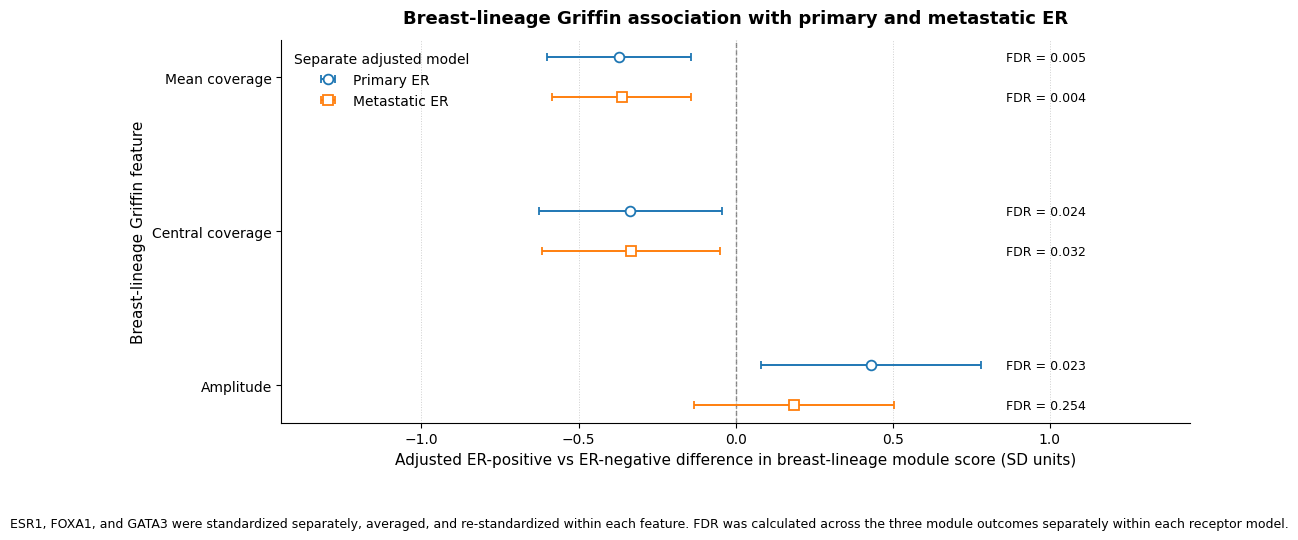

Forest-plot FDR labels drawn: 6

Analysis completed successfully.
Workbook: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_BreastLineage_Module_Primary_vs_Metastatic_ER/Griffin_BreastLineage_Primary_vs_Metastatic_ER_Module_Analysis.xlsx
Model results CSV: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_BreastLineage_Module_Primary_vs_Metastatic_ER/Griffin_BreastLineage_Module_Model_Results.csv
Analysis cohort CSV: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_BreastLineage_Module_Primary_vs_Metastatic_ER/Griffin_BreastLineage_Module_Analysis_Cohort.csv
Forest PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_BreastLineage_Module_Primary_vs_Metastatic_ER/Griffin_BreastLineage_Primary_vs_Metastatic_ER_Module_Forest.png
Forest PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/Griffin_BreastLineage_Module_Primary_vs_Metastatic_ER/G

In [18]:
"""
AURORA Griffin breast-lineage module analysis
==============================================

Scientific question
-------------------
Are coordinated ESR1-, FOXA1-, and GATA3-centered Griffin nucleosome
features associated with primary-tumor ER status or metastatic ER status?

Primary analysis
----------------
1. Select one first cfDNA draw per patient using the lowest NB number.
2. Use ESR1, FOXA1, and GATA3 together as a breast-lineage module.
3. Build one standardized breast-lineage module score for each feature:
      - mean coverage
      - central coverage
      - amplitude
4. Fit two SEPARATE adjusted HC3-robust linear models for every module score:
      Griffin module ~ primary ER + covariates
      Griffin module ~ metastatic ER + covariates
   Primary and metastatic ER are never included together in one model.
5. Use tumor fraction per 1 percentage-point increase.
6. Apply Benjamini-Hochberg FDR across the three module outcomes separately
   for the primary-ER model family and metastatic-ER model family.

Module construction
-------------------
For each feature, ESR1, FOXA1, and GATA3 are first standardized separately
within the final analysis cohort. Their three z scores are averaged, and the
resulting average is standardized again. Therefore, model coefficients are
reported in breast-lineage module standard-deviation units.

The script uses one first draw per patient; this is not a longitudinal model.

Required packages
-----------------
pandas, numpy, statsmodels, scipy, matplotlib, openpyxl
"""

# %%
# ============================================================
# 1. Imports
# ============================================================

from __future__ import annotations

import re
import warnings
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from openpyxl import load_workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)

SCRIPT_VERSION = "2026-08-01-breast-lineage-module-per1pct-v2"
print(f"Running script version: {SCRIPT_VERSION}")


# %%
# ============================================================
# 2. User settings — edit only this section
# ============================================================

# Input paths used for the verified run. Replace with your project paths.
CLINICAL_PATH = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx"
)

FIRST_PRIMARY_METASHEET_PATH = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/"
    "Metasheet_Analysis.with_Histology_Receptor_status.First_Primary.xlsx"
)

EARLIEST_MET_METASHEET_PATH = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/"
    "Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx"
)

GRIFFIN_PATH = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/"
    "Griffin_22TF_GC_corrected_summary_by_module.xlsx"
)

# Change this location as needed.
OUTPUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/"
    "Griffin_BreastLineage_Module_Primary_vs_Metastatic_ER"
)

# Run one or both separate receptor models.
# Allowed values: "primary_ER", "metastatic_ER"
RUN_RECEPTOR_MODELS = ["primary_ER", "metastatic_ER"]

# All receptor models listed above are fitted on one common complete-case
# cohort. If only one receptor model is listed, only that receptor status is
# required to be known.

# Known ambiguous treatment-timing records.
TREATMENT_CONTEXT_OVERRIDES = {
    "588-6": "Unknown",
    "995-4": "Unknown",
}

# Match the earlier fully adjusted workflow: ambiguous treatment records are
# excluded from the full model by setting metastatic burden to missing.
EXCLUDE_AMBIGUOUS_TREATMENT_FROM_FULL_MODEL = True

TARGET_TFBS = ["ESR1", "FOXA1", "GATA3"]
FEATURES = {
    "mean_coverage": "Mean coverage",
    "central_coverage": "Central coverage",
    "amplitude": "Amplitude",
}

STATUS_ORDER = ["Positive", "Negative", "Unknown"]

THERAPY_CATEGORIES = {
    "Met_Targeted_Therapy",
    "Met_Chemotherapy",
    "Met_Hormonal_Therapy",
}

# Fixed baseline covariates used in both models for direct comparability.
ADJUSTMENT_TERMS = [
    "tumor_fraction_per1pct",
    "C(treatment_context)",
    "metastatic_burden",
    "C(primary_HER2)",
    "C(primary_histology)",
    "years_from_met_dx",
]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_XLSX = OUTPUT_DIR / (
    "Griffin_BreastLineage_Primary_vs_Metastatic_ER_Module_Analysis.xlsx"
)
OUTPUT_RESULTS_CSV = OUTPUT_DIR / (
    "Griffin_BreastLineage_Module_Model_Results.csv"
)
OUTPUT_COHORT_CSV = OUTPUT_DIR / (
    "Griffin_BreastLineage_Module_Analysis_Cohort.csv"
)
OUTPUT_FOREST_PNG = OUTPUT_DIR / (
    "Griffin_BreastLineage_Primary_vs_Metastatic_ER_Module_Forest.png"
)
OUTPUT_FOREST_PDF = OUTPUT_DIR / (
    "Griffin_BreastLineage_Primary_vs_Metastatic_ER_Module_Forest.pdf"
)


# %%
# ============================================================
# 3. General utility functions
# ============================================================


def require_file(path: Path, label: str) -> None:
    """Stop immediately if an input file is absent."""
    if not path.is_file():
        raise FileNotFoundError(f"{label} not found:\n{path}")


def find_sheet_with_columns(
    workbook_path: Path,
    required_columns: Iterable[str],
) -> str:
    """Return the first worksheet containing all required columns."""
    required = set(required_columns)
    workbook = pd.ExcelFile(workbook_path)

    for sheet_name in workbook.sheet_names:
        columns = set(
            pd.read_excel(
                workbook_path,
                sheet_name=sheet_name,
                nrows=0,
            ).columns
        )
        if required.issubset(columns):
            return sheet_name

    raise ValueError(
        f"No sheet in {workbook_path} contains required columns: "
        f"{sorted(required)}"
    )


def normalize_patient_id(value: object) -> str:
    """Normalize patient identifiers read as text or numbers."""
    if pd.isna(value):
        return ""
    return re.sub(r"\.0$", "", str(value).strip())


def normalize_sample(value: object) -> str:
    """Remove an optional AUP- prefix from sample identifiers."""
    if pd.isna(value):
        return ""
    return re.sub(r"^AUP-", "", str(value).strip())


def nb_number(sample: object) -> int:
    """Extract NB number; samples without an NB suffix sort last."""
    match = re.search(r"-NB(\d+)$", str(sample))
    return int(match.group(1)) if match else 10**9


def normalize_status(value: object) -> str:
    """Normalize receptor values to Positive, Negative, or Unknown."""
    if pd.isna(value):
        return "Unknown"

    text = str(value).strip().lower()
    if text in {"positive", "pos", "+", "1", "yes", "true"}:
        return "Positive"
    if text in {"negative", "neg", "-", "0", "no", "false"}:
        return "Negative"
    return "Unknown"


def normalize_histology(value: object) -> str:
    """Collapse histology to stable analysis categories."""
    if pd.isna(value):
        return "Unknown"

    text = str(value).strip().lower()
    if "mixed" in text or ("duct" in text and "lob" in text):
        return "Mixed"
    if "lob" in text:
        return "Lobular"
    if "duct" in text:
        return "Ductal"
    return "Unknown"


def normalize_metastatic_site(value: object) -> Optional[str]:
    """Collapse metastatic tissue-site labels into organ categories."""
    if pd.isna(value):
        return None

    text = str(value).strip().lower()
    if not text:
        return None

    site_patterns = {
        "Bone": ["bone", "osseous", "spine", "vertebra", "rib", "hip"],
        "Liver": ["liver", "hepatic"],
        "Lung/Pleura": ["lung", "pleura", "pulmonary"],
        "Brain/CNS": ["brain", "cns", "cereb", "mening", "lepto"],
        "Lymph node": ["lymph", "node", "axilla"],
        "Skin/Soft tissue": ["skin", "soft tissue", "chest wall"],
        "Breast": ["breast"],
        "Other": [
            "ovary", "peritone", "adrenal", "kidney", "spleen",
            "thyroid", "pericard", "ascites", "ureter",
        ],
    }

    for category, patterns in site_patterns.items():
        if any(pattern in text for pattern in patterns):
            return category
    return "Other"


def bh_fdr(values: Sequence[float]) -> np.ndarray:
    """Benjamini-Hochberg FDR while preserving missing values."""
    array = np.asarray(values, dtype=float)
    output = np.full(array.shape, np.nan, dtype=float)
    valid = np.isfinite(array)
    if valid.any():
        output[valid] = multipletests(
            array[valid],
            method="fdr_bh",
        )[1]
    return output


def one_value_per_patient(
    group: pd.Series,
    column_name: str,
    patient_id: str,
) -> object:
    """Return one stable value per patient or stop on inconsistency."""
    values: List[str] = []
    for value in group.tolist():
        if pd.isna(value):
            continue
        text = str(value).strip()
        if text.lower() not in {"", "none", "nan", "na", "n/a"}:
            values.append(text)

    unique = list(dict.fromkeys(values))
    if len(unique) > 1:
        raise ValueError(
            f"Patient {patient_id} has inconsistent {column_name}: {unique}"
        )
    return unique[0] if unique else np.nan


def collapse_receptor_metasheet(
    metasheet: pd.DataFrame,
    source_name: str,
) -> pd.DataFrame:
    """Collapse a receptor-specific sample metasheet to one row/patient."""
    required = {
        "Patient_id",
        "ER_Status",
        "PR_Status",
        "HER2_Status",
        "Histological_subtype",
    }
    missing = required - set(metasheet.columns)
    if missing:
        raise ValueError(
            f"{source_name} metasheet is missing columns: {sorted(missing)}"
        )

    data = metasheet.copy()
    data["patient_id"] = data["Patient_id"].map(normalize_patient_id)

    rows: List[Dict[str, object]] = []
    for patient_id, patient_rows in data.groupby("patient_id", sort=False):
        er = normalize_status(
            one_value_per_patient(
                patient_rows["ER_Status"], "ER_Status", patient_id
            )
        )
        pr = normalize_status(
            one_value_per_patient(
                patient_rows["PR_Status"], "PR_Status", patient_id
            )
        )
        her2 = normalize_status(
            one_value_per_patient(
                patient_rows["HER2_Status"], "HER2_Status", patient_id
            )
        )
        histology = normalize_histology(
            one_value_per_patient(
                patient_rows["Histological_subtype"],
                "Histological_subtype",
                patient_id,
            )
        )

        rows.append(
            {
                "patient_id": patient_id,
                f"{source_name}_ER": er,
                f"{source_name}_PR": pr,
                f"{source_name}_HER2": her2,
                f"{source_name}_histology": histology,
            }
        )

    return (
        pd.DataFrame(rows)
        .sort_values("patient_id")
        .reset_index(drop=True)
    )


def infer_treatment_context(
    patient_rows: pd.DataFrame,
    draw_day: float,
    patient_id: str,
) -> str:
    """Assign first draw as pre-, on-, post/off-treatment, or unknown."""
    if patient_id in TREATMENT_CONTEXT_OVERRIDES:
        return TREATMENT_CONTEXT_OVERRIDES[patient_id]

    therapy = patient_rows[
        patient_rows["Category"].isin(THERAPY_CATEGORIES)
    ].copy()

    therapy["start_day"] = pd.to_numeric(
        therapy["Days_From_Primary_Diagnosis"],
        errors="coerce",
    )
    therapy["end_day"] = pd.to_numeric(
        therapy.get("EndTrt_Days_From_Primary_Diagnosis", np.nan),
        errors="coerce",
    )
    therapy = therapy[therapy["start_day"].notna()].copy()

    if therapy.empty:
        return "Unknown"

    intervals: List[Tuple[float, float]] = []
    start_days = sorted(
        therapy["start_day"].dropna().astype(float).unique()
    )

    progression_days = pd.to_numeric(
        patient_rows.loc[
            patient_rows["Category"].eq("Progression_onTx"),
            "Days_From_Primary_Diagnosis",
        ],
        errors="coerce",
    ).dropna().astype(float).tolist()

    for row in therapy.itertuples(index=False):
        start_day = float(row.start_day)
        end_value = row.end_day

        if pd.notna(end_value):
            end_day = float(end_value)
        else:
            possible_ends = [day for day in start_days if day > start_day]
            possible_ends.extend(
                day for day in progression_days if day >= start_day
            )
            end_day = (
                min(possible_ends) - 1e-6
                if possible_ends
                else np.inf
            )

        intervals.append((start_day, end_day))

    if any(start <= draw_day <= end for start, end in intervals):
        return "On-treatment"
    if draw_day < min(start for start, _ in intervals):
        return "Pre-treatment"
    return "Post/Off-treatment"


def partial_r_squared(
    full_model,
    reduced_formula: str,
    data: pd.DataFrame,
) -> float:
    """Partial R-squared based on full and reduced-model residual SSE."""
    reduced_model = smf.ols(reduced_formula, data=data).fit()
    sse_full = float(np.sum(np.square(full_model.resid)))
    sse_reduced = float(np.sum(np.square(reduced_model.resid)))
    if sse_reduced <= 0:
        return np.nan
    return max(0.0, (sse_reduced - sse_full) / sse_reduced)


def safe_zscore(values: pd.Series, label: str) -> pd.Series:
    """Sample-SD z score with explicit zero-variance protection."""
    numeric = pd.to_numeric(values, errors="coerce")
    mean_value = numeric.mean()
    sd_value = numeric.std(ddof=1)

    if not np.isfinite(sd_value) or sd_value <= 0:
        raise ValueError(
            f"Cannot standardize {label}: SD is missing or zero."
        )

    return (numeric - mean_value) / sd_value


def format_fdr(value: float) -> str:
    """Compact FDR label for publication figures."""
    if not np.isfinite(value):
        return "FDR = NA"
    if value < 0.001:
        return "FDR < 0.001"
    return f"FDR = {value:.3f}"


# %%
# ============================================================
# 4. Load and validate inputs
# ============================================================

for input_path, label in [
    (CLINICAL_PATH, "Clinical workbook"),
    (FIRST_PRIMARY_METASHEET_PATH, "First-primary metasheet"),
    (EARLIEST_MET_METASHEET_PATH, "Earliest-metastatic metasheet"),
    (GRIFFIN_PATH, "Griffin workbook"),
]:
    require_file(input_path, label)

allowed_models = {"primary_ER", "metastatic_ER"}
invalid_models = set(RUN_RECEPTOR_MODELS) - allowed_models
if invalid_models:
    raise ValueError(
        f"Invalid RUN_RECEPTOR_MODELS values: {sorted(invalid_models)}"
    )
if not RUN_RECEPTOR_MODELS:
    raise ValueError("RUN_RECEPTOR_MODELS cannot be empty.")

clinical_sheet = find_sheet_with_columns(
    CLINICAL_PATH,
    {
        "patient_id",
        "Category",
        "Days_From_Primary_Diagnosis",
        "Barcode",
        "Site",
        "Tissue_Site",
        "Met_Therapy_Line",
    },
)

clinical = pd.read_excel(
    CLINICAL_PATH,
    sheet_name=clinical_sheet,
)
primary_meta = pd.read_excel(FIRST_PRIMARY_METASHEET_PATH)
metastatic_meta = pd.read_excel(EARLIEST_MET_METASHEET_PATH)
griffin_long = pd.read_excel(
    GRIFFIN_PATH,
    sheet_name="All_TFBS_Long",
)

print("Clinical workbook:", CLINICAL_PATH)
print("Clinical sheet:", clinical_sheet)
print("Primary receptor metasheet:", FIRST_PRIMARY_METASHEET_PATH)
print("Metastatic receptor metasheet:", EARLIEST_MET_METASHEET_PATH)
print("Griffin workbook:", GRIFFIN_PATH)
print("Output directory:", OUTPUT_DIR)
print("Separate receptor models:", RUN_RECEPTOR_MODELS)


# %%
# ============================================================
# 5. Build patient-level receptor table
# ============================================================

primary_receptors = collapse_receptor_metasheet(
    primary_meta,
    source_name="primary",
)
metastatic_receptors = collapse_receptor_metasheet(
    metastatic_meta,
    source_name="metastatic",
)

primary_ids = set(primary_receptors["patient_id"])
metastatic_ids = set(metastatic_receptors["patient_id"])
if primary_ids != metastatic_ids:
    raise ValueError(
        "Primary and metastatic receptor metasheets contain different "
        "patient sets."
    )

patient_receptors = primary_receptors.merge(
    metastatic_receptors,
    on="patient_id",
    how="inner",
    validate="one_to_one",
)

print("Receptor-profiled patients:", patient_receptors.shape[0])

receptor_count_rows: List[Dict[str, object]] = []
for receptor_source in ["primary", "metastatic"]:
    for receptor in ["ER", "PR", "HER2"]:
        column = f"{receptor_source}_{receptor}"
        counts = (
            patient_receptors[column]
            .value_counts(dropna=False)
            .reindex(STATUS_ORDER, fill_value=0)
        )
        for status, count in counts.items():
            receptor_count_rows.append(
                {
                    "Receptor_source": receptor_source,
                    "Receptor": receptor,
                    "Status": status,
                    "N": int(count),
                    "Percent": (
                        100.0 * float(count) / patient_receptors.shape[0]
                    ),
                }
            )
receptor_counts = pd.DataFrame(receptor_count_rows)

er_concordance = pd.crosstab(
    patient_receptors["primary_ER"],
    patient_receptors["metastatic_ER"],
    dropna=False,
).reindex(
    index=STATUS_ORDER,
    columns=STATUS_ORDER,
    fill_value=0,
)


# %%
# ============================================================
# 6. Select one first draw per patient and derive covariates
# ============================================================

required_meta_columns = {
    "Collaborator_sample_id",
    "Patient_id",
    "Patient_Identifier",
    "Tumor_Fraction",
}
for metadata, label in [
    (primary_meta, "Primary metasheet"),
    (metastatic_meta, "Metastatic metasheet"),
]:
    missing = required_meta_columns - set(metadata.columns)
    if missing:
        raise ValueError(f"{label} is missing columns: {sorted(missing)}")


def sample_tfx_table(metadata: pd.DataFrame) -> pd.DataFrame:
    table = metadata.copy()
    table["sample"] = table["Collaborator_sample_id"].map(
        normalize_sample
    )
    table["patient_id"] = table["Patient_id"].map(
        normalize_patient_id
    )
    table["tumor_fraction"] = pd.to_numeric(
        table["Tumor_Fraction"],
        errors="coerce",
    )
    return table[
        ["patient_id", "sample", "tumor_fraction"]
    ].drop_duplicates()


primary_sample_tfx = sample_tfx_table(primary_meta)
metastatic_sample_tfx = sample_tfx_table(metastatic_meta)

tfx_check = primary_sample_tfx.merge(
    metastatic_sample_tfx,
    on=["patient_id", "sample"],
    how="outer",
    suffixes=("_primary", "_metastatic"),
    indicator=True,
)
if not tfx_check["_merge"].eq("both").all():
    raise ValueError("The two metasheets do not contain identical samples.")

finite_pair = (
    tfx_check["tumor_fraction_primary"].notna()
    & tfx_check["tumor_fraction_metastatic"].notna()
)
if finite_pair.any():
    maximum_tfx_difference = (
        tfx_check.loc[finite_pair, "tumor_fraction_primary"]
        - tfx_check.loc[finite_pair, "tumor_fraction_metastatic"]
    ).abs().max()
    if maximum_tfx_difference > 1e-10:
        raise ValueError(
            "Tumor fraction differs between receptor-specific metasheets; "
            f"maximum difference={maximum_tfx_difference}."
        )

first_draw_source = primary_meta.copy()
first_draw_source["sample"] = first_draw_source[
    "Collaborator_sample_id"
].map(normalize_sample)
first_draw_source["patient_id"] = first_draw_source[
    "Patient_id"
].map(normalize_patient_id)
first_draw_source["NB_number"] = first_draw_source["sample"].map(
    nb_number
)
first_draw_source["tumor_fraction"] = pd.to_numeric(
    first_draw_source["Tumor_Fraction"],
    errors="coerce",
)

first_draw = (
    first_draw_source
    .sort_values(["patient_id", "NB_number", "sample"])
    .drop_duplicates("patient_id", keep="first")
    [["patient_id", "Patient_Identifier", "sample", "tumor_fraction"]]
    .rename(columns={"Patient_Identifier": "patient_identifier"})
)

first_draw = first_draw.merge(
    patient_receptors,
    on="patient_id",
    how="left",
    validate="one_to_one",
)

# Tumor fraction is stored as a proportion. Multiplication by 100 creates
# percentage-point units, so one regression unit equals a 1%-point increase.
first_draw["tumor_fraction_percent"] = (
    first_draw["tumor_fraction"] * 100.0
)
first_draw["tumor_fraction_per1pct"] = (
    first_draw["tumor_fraction_percent"]
)

clinical = clinical.copy()
clinical["patient_id"] = clinical["patient_id"].map(
    normalize_patient_id
)
clinical["clinical_sample"] = clinical["Barcode"].map(
    normalize_sample
)
clinical["clinical_day"] = pd.to_numeric(
    clinical["Days_From_Primary_Diagnosis"],
    errors="coerce",
)

blood_draw_rows = (
    clinical.loc[
        clinical["Category"].eq("Blood_Draw"),
        ["patient_id", "clinical_sample", "clinical_day", "Site"],
    ]
    .drop_duplicates(["patient_id", "clinical_sample"], keep="first")
    .rename(
        columns={
            "clinical_sample": "sample",
            "clinical_day": "draw_day",
            "Site": "clinical_center",
        }
    )
)

first_draw = first_draw.merge(
    blood_draw_rows,
    on=["patient_id", "sample"],
    how="left",
    validate="one_to_one",
)

if first_draw["draw_day"].isna().any():
    missing_samples = first_draw.loc[
        first_draw["draw_day"].isna(),
        "sample",
    ].tolist()
    raise ValueError(
        "Could not match first draws to clinical Blood_Draw rows: "
        + ", ".join(missing_samples[:20])
    )

clinical_by_patient = {
    patient_id: rows.copy()
    for patient_id, rows in clinical.groupby("patient_id")
}

metastatic_rows = clinical.loc[
    clinical["Category"].eq("Met_Diagnosis"),
    ["patient_id", "clinical_day", "Tissue_Site"],
].copy()
metastatic_rows["organ_category"] = metastatic_rows[
    "Tissue_Site"
].map(normalize_metastatic_site)

metastatic_by_patient = {
    patient_id: rows.copy()
    for patient_id, rows in metastatic_rows.groupby("patient_id")
}

treatment_context_values: List[str] = []
metastatic_burden_values: List[float] = []
years_from_met_dx_values: List[float] = []

for row in first_draw.itertuples(index=False):
    patient_rows = clinical_by_patient.get(
        row.patient_id,
        pd.DataFrame(columns=clinical.columns),
    )

    treatment_context = infer_treatment_context(
        patient_rows=patient_rows,
        draw_day=float(row.draw_day),
        patient_id=row.patient_id,
    )

    patient_metastases = metastatic_by_patient.get(
        row.patient_id,
        pd.DataFrame(columns=metastatic_rows.columns),
    )

    prior_metastases = patient_metastases[
        patient_metastases["clinical_day"] <= float(row.draw_day)
    ]
    metastatic_burden = float(
        prior_metastases["organ_category"].dropna().nunique()
    )

    metastatic_days = patient_metastases["clinical_day"].dropna()
    if metastatic_days.empty:
        years_from_met_dx = np.nan
    else:
        years_from_met_dx = (
            float(row.draw_day) - float(metastatic_days.min())
        ) / 365.25

    if (
        EXCLUDE_AMBIGUOUS_TREATMENT_FROM_FULL_MODEL
        and treatment_context == "Unknown"
    ):
        metastatic_burden = np.nan

    treatment_context_values.append(treatment_context)
    metastatic_burden_values.append(metastatic_burden)
    years_from_met_dx_values.append(years_from_met_dx)

first_draw["treatment_context"] = treatment_context_values
first_draw["metastatic_burden"] = metastatic_burden_values
first_draw["years_from_met_dx"] = years_from_met_dx_values
first_draw["clinical_center"] = (
    first_draw["clinical_center"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# Fixed baseline covariates used by both separate ER models.
first_draw["primary_HER2"] = (
    first_draw["primary_HER2"].fillna("Unknown")
)
first_draw["primary_histology"] = (
    first_draw["primary_histology"].fillna("Unknown")
)


# %%
# ============================================================
# 7. Create ESR1–FOXA1–GATA3 breast-lineage module scores
# ============================================================

required_griffin_columns = {
    "sample",
    "site_name",
    "mean_coverage",
    "central_coverage",
    "amplitude",
}
missing_griffin = required_griffin_columns - set(griffin_long.columns)
if missing_griffin:
    raise ValueError(
        f"All_TFBS_Long is missing columns: {sorted(missing_griffin)}"
    )

griffin_long = griffin_long.copy()
griffin_long["sample"] = griffin_long["sample"].map(
    normalize_sample
)

breast_lineage_long = griffin_long[
    griffin_long["site_name"].isin(TARGET_TFBS)
].copy()

# Validate one row per sample, TFBS.
duplicate_keys = breast_lineage_long.duplicated(
    ["sample", "site_name"],
    keep=False,
)
if duplicate_keys.any():
    duplicate_preview = breast_lineage_long.loc[
        duplicate_keys,
        ["sample", "site_name"],
    ].head(20)
    raise ValueError(
        "Duplicate sample-TFBS rows found in Griffin data:\n"
        + duplicate_preview.to_string(index=False)
    )

wide_parts: List[pd.DataFrame] = []
for feature in FEATURES:
    part = breast_lineage_long.pivot(
        index="sample",
        columns="site_name",
        values=feature,
    )
    part = part.reindex(columns=TARGET_TFBS)
    part.columns = [
        f"{feature}_{tfbs}" for tfbs in TARGET_TFBS
    ]
    wide_parts.append(part)

breast_lineage_wide = pd.concat(wide_parts, axis=1).reset_index()

analysis_base = first_draw.merge(
    breast_lineage_wide,
    on="sample",
    how="left",
    validate="one_to_one",
)

component_columns = [
    f"{feature}_{tfbs}"
    for feature in FEATURES
    for tfbs in TARGET_TFBS
]

common_required = [
    "tumor_fraction_per1pct",
    "treatment_context",
    "metastatic_burden",
    "primary_HER2",
    "primary_histology",
    "years_from_met_dx",
] + component_columns

# Use one common complete-case cohort across all selected receptor models.
receptor_required = list(RUN_RECEPTOR_MODELS)

analysis_cohort = analysis_base.copy()
for receptor_column in receptor_required:
    analysis_cohort = analysis_cohort[
        analysis_cohort[receptor_column].isin(["Positive", "Negative"])
    ].copy()

analysis_cohort = analysis_cohort.dropna(
    subset=common_required
).copy()

if analysis_cohort.empty:
    raise ValueError("The complete-case analysis cohort is empty.")

# Build module scores only after final cohort selection.
component_qc_rows: List[Dict[str, object]] = []
for feature, feature_label in FEATURES.items():
    z_columns: List[str] = []

    for tfbs in TARGET_TFBS:
        raw_column = f"{feature}_{tfbs}"
        z_column = f"{raw_column}_z"
        analysis_cohort[z_column] = safe_zscore(
            analysis_cohort[raw_column],
            label=raw_column,
        )
        z_columns.append(z_column)

        component_qc_rows.append(
            {
                "Feature": feature_label,
                "TFBS": tfbs,
                "Raw_column": raw_column,
                "N": int(analysis_cohort[raw_column].notna().sum()),
                "Raw_mean": float(analysis_cohort[raw_column].mean()),
                "Raw_SD": float(
                    analysis_cohort[raw_column].std(ddof=1)
                ),
            }
        )

    average_column = f"breast_lineage_{feature}_average_z"
    module_column = f"breast_lineage_{feature}_module_z"

    analysis_cohort[average_column] = analysis_cohort[
        z_columns
    ].mean(axis=1)

    # Re-standardize the average so every module outcome has SD=1.
    analysis_cohort[module_column] = safe_zscore(
        analysis_cohort[average_column],
        label=average_column,
    )

component_qc = pd.DataFrame(component_qc_rows)

module_outcomes = {
    "mean_coverage": "breast_lineage_mean_coverage_module_z",
    "central_coverage": "breast_lineage_central_coverage_module_z",
    "amplitude": "breast_lineage_amplitude_module_z",
}

print("\nFinal complete-case analysis cohort")
print("Patients:", analysis_cohort["patient_id"].nunique())
for receptor_column in RUN_RECEPTOR_MODELS:
    counts = analysis_cohort[receptor_column].value_counts()
    print(
        f"{receptor_column}: ER+={int(counts.get('Positive', 0))}, "
        f"ER-={int(counts.get('Negative', 0))}"
    )


# %%
# ============================================================
# 8. Fit separate primary-ER and metastatic-ER models
# ============================================================


def fit_module_model(
    data: pd.DataFrame,
    feature_key: str,
    receptor_column: str,
) -> Dict[str, object]:
    """Fit one HC3-robust breast-lineage module association model."""
    outcome = module_outcomes[feature_key]
    receptor_term = (
        f"C({receptor_column}, Treatment(reference='Negative'))"
    )
    formula = outcome + " ~ " + " + ".join(
        [receptor_term] + ADJUSTMENT_TERMS
    )

    model = smf.ols(
        formula=formula,
        data=data,
    ).fit(cov_type="HC3")

    coefficient_name = (
        f"C({receptor_column}, Treatment(reference='Negative'))"
        "[T.Positive]"
    )

    beta = float(model.params[coefficient_name])
    se = float(model.bse[coefficient_name])
    p_value = float(model.pvalues[coefficient_name])

    reduced_formula = outcome + " ~ " + " + ".join(
        ADJUSTMENT_TERMS
    )

    model_label = (
        "Primary ER"
        if receptor_column == "primary_ER"
        else "Metastatic ER"
    )

    return {
        "Model": model_label,
        "Receptor_column": receptor_column,
        "Feature": FEATURES[feature_key],
        "Outcome_column": outcome,
        "N": int(model.nobs),
        "ER_positive_N": int(
            data[receptor_column].eq("Positive").sum()
        ),
        "ER_negative_N": int(
            data[receptor_column].eq("Negative").sum()
        ),
        "Beta_ERpos_vs_ERneg_module_SD": beta,
        "SE": se,
        "CI95_low": beta - 1.959964 * se,
        "CI95_high": beta + 1.959964 * se,
        "P_value": p_value,
        "Partial_R2_ER": partial_r_squared(
            model,
            reduced_formula,
            data,
        ),
        "Adjusted_R2": float(model.rsquared_adj),
        "AIC": float(model.aic),
        "BIC": float(model.bic),
        "Tumor_fraction_beta_per1pct": float(
            model.params.get("tumor_fraction_per1pct", np.nan)
        ),
        "Tumor_fraction_P_value": float(
            model.pvalues.get("tumor_fraction_per1pct", np.nan)
        ),
        "Formula": formula,
    }


model_rows: List[Dict[str, object]] = []
for receptor_column in RUN_RECEPTOR_MODELS:
    for feature_key in FEATURES:
        model_rows.append(
            fit_module_model(
                data=analysis_cohort,
                feature_key=feature_key,
                receptor_column=receptor_column,
            )
        )

model_results = pd.DataFrame(model_rows)

# FDR across the three breast-lineage outcomes separately within each model.
model_results["FDR_across_3_module_features"] = (
    model_results
    .groupby("Model", observed=True)["P_value"]
    .transform(lambda values: bh_fdr(values))
)

feature_order = list(FEATURES.values())
model_order = [
    model
    for model in ["Primary ER", "Metastatic ER"]
    if model in set(model_results["Model"])
]

model_results["Feature"] = pd.Categorical(
    model_results["Feature"],
    categories=feature_order,
    ordered=True,
)
model_results["Model"] = pd.Categorical(
    model_results["Model"],
    categories=model_order,
    ordered=True,
)
model_results = model_results.sort_values(
    ["Feature", "Model"]
).reset_index(drop=True)

print("\nSeparate breast-lineage module models")
print(
    model_results[
        [
            "Model",
            "Feature",
            "N",
            "Beta_ERpos_vs_ERneg_module_SD",
            "CI95_low",
            "CI95_high",
            "P_value",
            "FDR_across_3_module_features",
            "Partial_R2_ER",
            "AIC",
        ]
    ].to_string(index=False)
)


# %%
# ============================================================
# 9. Direct same-cohort descriptive model comparison
# ============================================================

if {"Primary ER", "Metastatic ER"}.issubset(
    set(model_results["Model"].astype(str))
):
    primary_results = model_results[
        model_results["Model"].astype(str).eq("Primary ER")
    ].copy()
    metastatic_results = model_results[
        model_results["Model"].astype(str).eq("Metastatic ER")
    ].copy()

    model_comparison = primary_results.merge(
        metastatic_results,
        on=["Feature", "N"],
        suffixes=("_Primary", "_Metastatic"),
        validate="one_to_one",
    )

    model_comparison["Delta_AIC_Primary_minus_Metastatic"] = (
        model_comparison["AIC_Primary"]
        - model_comparison["AIC_Metastatic"]
    )
    model_comparison["Lower_AIC_model"] = np.where(
        model_comparison[
            "Delta_AIC_Primary_minus_Metastatic"
        ] > 0,
        "Metastatic ER",
        "Primary ER",
    )
    model_comparison["Delta_partial_R2_Metastatic_minus_Primary"] = (
        model_comparison["Partial_R2_ER_Metastatic"]
        - model_comparison["Partial_R2_ER_Primary"]
    )
else:
    model_comparison = pd.DataFrame()


# %%
# ============================================================
# 10. Descriptive module-score summaries
# ============================================================

raw_descriptive_rows: List[Dict[str, object]] = []
for receptor_column in RUN_RECEPTOR_MODELS:
    model_label = (
        "Primary ER"
        if receptor_column == "primary_ER"
        else "Metastatic ER"
    )
    for feature_key, feature_label in FEATURES.items():
        outcome = module_outcomes[feature_key]
        for er_status, group in analysis_cohort.groupby(
            receptor_column,
            observed=True,
        ):
            values = pd.to_numeric(
                group[outcome],
                errors="coerce",
            ).dropna()
            raw_descriptive_rows.append(
                {
                    "Model": model_label,
                    "Feature": feature_label,
                    "ER_status": er_status,
                    "N": int(len(values)),
                    "Mean_module_z": float(values.mean()),
                    "SD_module_z": float(values.std(ddof=1)),
                    "Median_module_z": float(values.median()),
                    "Q1_module_z": float(values.quantile(0.25)),
                    "Q3_module_z": float(values.quantile(0.75)),
                }
            )

module_descriptives = pd.DataFrame(raw_descriptive_rows)


# %%
# ============================================================
# 11. Publication forest plot — all six FDR values shown
# ============================================================


def plot_module_forest(
    results: pd.DataFrame,
    png_path: Path,
    pdf_path: Path,
) -> None:
    """
    Plot primary-ER and metastatic-ER module estimates.

    Every model-feature estimate is annotated with its FDR. There is no
    significance-dependent marker filling or highlighting.
    """
    required = {
        "Model",
        "Feature",
        "Beta_ERpos_vs_ERneg_module_SD",
        "CI95_low",
        "CI95_high",
        "FDR_across_3_module_features",
    }
    missing = required - set(results.columns)
    if missing:
        raise ValueError(
            f"Forest-plot results missing columns: {sorted(missing)}"
        )

    expected_rows = len(feature_order) * len(model_order)
    if results.shape[0] != expected_rows:
        raise ValueError(
            f"Expected {expected_rows} forest rows, found {results.shape[0]}."
        )

    duplicate_pairs = results.duplicated(["Feature", "Model"], keep=False)
    if duplicate_pairs.any():
        raise ValueError("Duplicate Feature-Model rows in forest-plot data.")

    plot_data = results.copy()
    plot_data["Feature"] = pd.Categorical(
        plot_data["Feature"],
        categories=feature_order,
        ordered=True,
    )
    plot_data["Model"] = pd.Categorical(
        plot_data["Model"],
        categories=model_order,
        ordered=True,
    )
    plot_data = plot_data.sort_values(["Feature", "Model"])

    finite_limits = pd.concat(
        [plot_data["CI95_low"], plot_data["CI95_high"]],
        ignore_index=True,
    ).dropna()
    max_abs = max(0.25, float(np.abs(finite_limits).max()))
    x_limit = max_abs * 1.85
    label_x = max_abs * 1.10

    fig, ax = plt.subplots(figsize=(11.5, 5.8))

    y_base = np.arange(len(feature_order), dtype=float)
    offsets = np.linspace(-0.13, 0.13, num=len(model_order))
    markers = ["o", "s", "^", "D"]

    label_count = 0
    for model_index, model_label in enumerate(model_order):
        subset = (
            plot_data[
                plot_data["Model"].astype(str).eq(model_label)
            ]
            .set_index("Feature")
            .reindex(feature_order)
            .reset_index()
        )

        y_positions = y_base + offsets[model_index]
        beta = subset[
            "Beta_ERpos_vs_ERneg_module_SD"
        ].to_numpy(dtype=float)
        ci_low = subset["CI95_low"].to_numpy(dtype=float)
        ci_high = subset["CI95_high"].to_numpy(dtype=float)

        ax.errorbar(
            beta,
            y_positions,
            xerr=[beta - ci_low, ci_high - beta],
            fmt=markers[model_index],
            linestyle="none",
            markersize=7,
            markerfacecolor="white",
            markeredgewidth=1.3,
            capsize=3,
            elinewidth=1.4,
            label=model_label,
            zorder=3,
        )

        for row_index, row in subset.iterrows():
            fdr_value = float(row["FDR_across_3_module_features"])
            ax.text(
                label_x,
                y_positions[row_index],
                format_fdr(fdr_value),
                va="center",
                ha="left",
                fontsize=9,
            )
            label_count += 1

    if label_count != expected_rows:
        raise RuntimeError(
            f"Expected {expected_rows} FDR labels, drew {label_count}."
        )

    ax.axvline(0, linestyle="--", linewidth=1, color="gray", zorder=1)
    ax.set_yticks(y_base)
    ax.set_yticklabels(feature_order, fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(-x_limit, x_limit)
    ax.set_xlabel(
        "Adjusted ER-positive vs ER-negative difference "
        "in breast-lineage module score (SD units)",
        fontsize=11,
    )
    ax.set_ylabel("Breast-lineage Griffin feature", fontsize=11)
    ax.set_title(
        "Breast-lineage Griffin association with primary and metastatic ER",
        fontsize=13,
        fontweight="bold",
        pad=12,
    )
    ax.legend(title="Separate adjusted model", frameon=False, loc="upper left")
    ax.grid(axis="x", linestyle=":", linewidth=0.7, alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.text(
        0.5,
        0.015,
        "ESR1, FOXA1, and GATA3 were standardized separately, averaged, "
        "and re-standardized within each feature. FDR was calculated across "
        "the three module outcomes separately within each receptor model.",
        ha="center",
        va="bottom",
        fontsize=9,
    )

    fig.subplots_adjust(
        left=0.18,
        right=0.97,
        top=0.86,
        bottom=0.20,
    )

    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Forest-plot FDR labels drawn: {label_count}")


plot_module_forest(
    results=model_results,
    png_path=OUTPUT_FOREST_PNG,
    pdf_path=OUTPUT_FOREST_PDF,
)


# %%
# ============================================================
# 12. Methods/data-dictionary sheet
# ============================================================

methods_rows = [
    (
        "Scientific question",
        "Test whether a coordinated ESR1-FOXA1-GATA3 breast-lineage Griffin "
        "module is associated separately with primary ER status and metastatic "
        "ER status.",
    ),
    (
        "Separate models",
        "Primary ER and metastatic ER are never entered together. The fitted "
        "models are Griffin module ~ primary ER + covariates and Griffin module "
        "~ metastatic ER + covariates.",
    ),
    (
        "First-draw design",
        "One cfDNA sample per patient was selected using the lowest available "
        "NB number. The analysis is cross-sectional and not longitudinal.",
    ),
    (
        "Breast-lineage components",
        "The module contains Griffin measurements centered on ESR1, FOXA1, "
        "and GATA3 TF-binding sites.",
    ),
    (
        "Module construction",
        "For each Griffin feature, ESR1, FOXA1, and GATA3 were z-standardized "
        "separately in the final analysis cohort. The three z scores were "
        "averaged and the average was z-standardized again, yielding one "
        "breast-lineage module score with SD=1 per patient.",
    ),
    (
        "Module outcomes",
        "Three outcomes were analyzed separately: breast-lineage mean coverage, "
        "central coverage, and amplitude.",
    ),
    (
        "Primary ER model",
        "Breast-lineage Griffin module ~ primary ER + tumor fraction per 1 "
        "percentage point + treatment context + metastatic burden + primary "
        "HER2 + primary histology + years from metastatic diagnosis.",
    ),
    (
        "Metastatic ER model",
        "Breast-lineage Griffin module ~ metastatic ER + tumor fraction per 1 "
        "percentage point + treatment context + metastatic burden + primary "
        "HER2 + primary histology + years from metastatic diagnosis.",
    ),
    (
        "Common matched cohort",
        "All receptor models listed in RUN_RECEPTOR_MODELS use the same "
        "complete-case cohort. When both models are requested, patients must "
        "have known primary and metastatic ER, complete covariates, and all "
        "nine Griffin components.",
    ),
    (
        "tumor_fraction_per1pct",
        "Tumor fraction is stored as a proportion and multiplied by 100. One "
        "model unit therefore represents a 1-percentage-point increase in tumor "
        "fraction (for example, 5% to 6%).",
    ),
    (
        "ER coefficient",
        "Beta_ERpos_vs_ERneg_module_SD is the adjusted difference in the "
        "breast-lineage module score for ER-positive versus ER-negative cases, "
        "expressed in module standard-deviation units.",
    ),
    (
        "Confidence interval",
        "CI95_low and CI95_high are the HC3-robust 95% confidence interval for "
        "the ER-positive versus ER-negative coefficient.",
    ),
    (
        "P_value",
        "Two-sided HC3-robust P value for the ER-positive versus ER-negative "
        "coefficient in the indicated separate model.",
    ),
    (
        "FDR_across_3_module_features",
        "Benjamini-Hochberg FDR applied across mean coverage, central coverage, "
        "and amplitude separately within the primary-ER model family and within "
        "the metastatic-ER model family.",
    ),
    (
        "Partial_R2_ER",
        "Proportion of residual variation additionally explained by the ER term, "
        "calculated by comparing the full model with an otherwise identical "
        "model that excludes ER.",
    ),
    (
        "AIC comparison",
        "AIC is compared descriptively between primary-ER and metastatic-ER "
        "models only because the outcomes, cohort, and adjustment covariates are "
        "the same. Lower AIC indicates better relative fit.",
    ),
    (
        "Tumor_fraction_beta_per1pct",
        "Adjusted change in the standardized breast-lineage module outcome for "
        "each 1-percentage-point increase in tumor fraction.",
    ),
    (
        "Forest plot",
        "All model-feature estimates are shown using the same unfilled marker "
        "style within each model. Every estimate is annotated with its FDR; "
        "there is no significance-dependent highlighting.",
    ),
    (
        "Interpretation guardrail",
        "The analysis evaluates association with documented receptor phenotype. "
        "It does not demonstrate causality, direct TF occupancy, transcription, "
        "or prediction of a future receptor change.",
    ),
]

methods = pd.DataFrame(
    methods_rows,
    columns=["Method_item", "Description"],
)


# %%
# ============================================================
# 13. Save workbook and flat files
# ============================================================

analysis_export_columns = [
    "patient_id",
    "patient_identifier",
    "sample",
    "primary_ER",
    "metastatic_ER",
    "primary_PR",
    "metastatic_PR",
    "primary_HER2",
    "metastatic_HER2",
    "primary_histology",
    "metastatic_histology",
    "tumor_fraction",
    "tumor_fraction_percent",
    "tumor_fraction_per1pct",
    "treatment_context",
    "metastatic_burden",
    "years_from_met_dx",
    "breast_lineage_mean_coverage_module_z",
    "breast_lineage_central_coverage_module_z",
    "breast_lineage_amplitude_module_z",
] + component_columns

analysis_export = analysis_cohort[
    analysis_export_columns
].sort_values("patient_id")

model_results.to_csv(OUTPUT_RESULTS_CSV, index=False)
analysis_export.to_csv(OUTPUT_COHORT_CSV, index=False)

with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    model_results.to_excel(
        writer,
        sheet_name="Model_Results",
        index=False,
    )

    if not model_comparison.empty:
        model_comparison.to_excel(
            writer,
            sheet_name="Model_Comparison",
            index=False,
        )

    analysis_export.to_excel(
        writer,
        sheet_name="Analysis_Cohort",
        index=False,
    )

    module_descriptives.to_excel(
        writer,
        sheet_name="Module_Descriptives",
        index=False,
    )

    component_qc.to_excel(
        writer,
        sheet_name="Component_QC",
        index=False,
    )

    receptor_counts.to_excel(
        writer,
        sheet_name="Receptor_Counts",
        index=False,
    )

    er_concordance.to_excel(
        writer,
        sheet_name="ER_Concordance",
    )

    methods.to_excel(
        writer,
        sheet_name="Methods",
        index=False,
    )


# %%
# ============================================================
# 14. Format workbook
# ============================================================

workbook = load_workbook(OUTPUT_XLSX)
header_fill = PatternFill("solid", fgColor="1F4E78")
header_font = Font(bold=True, color="FFFFFF")

for worksheet in workbook.worksheets:
    worksheet.freeze_panes = "A2"
    worksheet.auto_filter.ref = worksheet.dimensions

    for cell in worksheet[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )

    for column_cells in worksheet.columns:
        max_length = 0
        for cell in column_cells:
            if cell.value is not None:
                max_length = max(max_length, len(str(cell.value)))

        width = min(max(max_length + 2, 12), 60)
        worksheet.column_dimensions[
            get_column_letter(column_cells[0].column)
        ].width = width

workbook.save(OUTPUT_XLSX)


# %%
# ============================================================
# 15. Final audit output
# ============================================================

print("\nAnalysis completed successfully.")
print("Workbook:", OUTPUT_XLSX)
print("Model results CSV:", OUTPUT_RESULTS_CSV)
print("Analysis cohort CSV:", OUTPUT_COHORT_CSV)
print("Forest PNG:", OUTPUT_FOREST_PNG)
print("Forest PDF:", OUTPUT_FOREST_PDF)

print("\nFDR values used in the forest plot:")
print(
    model_results[
        [
            "Model",
            "Feature",
            "FDR_across_3_module_features",
        ]
    ].to_string(index=False)
)

# ER concordance summary
paired_er = patient_receptors[
    patient_receptors["primary_ER"].isin(["Positive", "Negative"])
    & patient_receptors["metastatic_ER"].isin(["Positive", "Negative"])
].copy()

paired_er["ER_discordant"] = (
    paired_er["primary_ER"] != paired_er["metastatic_ER"]
)

print("\nER concordance summary")
print("----------------------")
print("Paired evaluable patients:", len(paired_er))
print("ER-concordant patients:", int((~paired_er["ER_discordant"]).sum()))
print("ER-discordant patients:", int(paired_er["ER_discordant"].sum()))

print("\nER transition counts")
print(
    paired_er.groupby(
        ["primary_ER", "metastatic_ER"]
    ).size().to_string()
)